# Lesotho POI data: visualising the engineered features

**Input:** `poi_engineered.csv` from `poi_feature_engineering.ipynb` (6,083 nodes, 66 model features with the prefixes
`loc_`, `adm_`, `struct_`, `attr_`, `ctx_`, plus the carried-over id, label, graph and split columns).
**Output:** figures only. Nothing is written to disk and nothing is trained.

The feature-engineering notebook checked each feature family on its own. This notebook looks at the 66 features
together, as the GNN will receive them, and asks the questions that matter for the model:

| Section | Question |
|---|---|
| 1 | What do the 66 features look like after the transforms? Are any badly scaled or near-constant? |
| 2 | Which features differ between the 8 categories, and in which direction? |
| 3 | For the most discriminating features, how much do the categories overlap? |
| 4 | How much redundancy is left between features? |
| 5 | How smooth is each feature on the k = 8 graph, and does a neighbour average carry more category signal than the node's own value? |
| 6 | Do nodes of the same category sit together in feature space, on the graph, or both? |
| 7 | How do the spatial CV folds differ in class balance and in feature values? |
| 8 | How large is the `osm_id_rank` mapping-bias effect the feature notebook warned about? |

**Rules followed here.**

- Everything is **descriptive**. Where features are standardised or labels are used (Sections 2 to 8), it is for
  display only, over all folds, and nothing is fed back into feature choice. The model notebook still fits its
  scaler on the training folds of each split.
- Only the POI data are used; no outside data are added.
- Colour: one hue (blue) when the categories are on an axis; one category highlighted in blue against grey when they
  share a map or scatter; red–grey–blue for signed values. The chart style is the same as in `poi_eda.ipynb` and
  `poi_feature_engineering.ipynb`.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import stats
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

IN_CSV = "poi_engineered.csv"
FEAT_RE = r"^(loc|adm|struct|attr|ctx)_"
K = 8          # k-NN graph used by the EDA, the structural encodings and the model
SEED = 42

# Chart styling (same as poi_eda.ipynb and poi_feature_engineering.ipynb)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf",
                                                     "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#b52f2f", "#e98f8e", "#f0efec", "#86b6ef", "#184f95"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.dpi": 100, "legend.frameon": False,
})

df = pd.read_csv(IN_CSV, keep_default_na=False, na_values=[""])
FEATS = df.filter(regex=FEAT_RE).columns.tolist()
GROUPS = ["loc", "adm", "struct", "attr", "ctx"]
GROUP_NAMES = {"loc": "Location", "adm": "Administrative", "struct": "Graph structure", "attr": "Node mapping",
               "ctx": "Area mapping"}
group_of = {c: c.split("_")[0] for c in FEATS}

N = len(df)
assert df["node_id"].tolist() == list(range(N))
assert np.isfinite(df[FEATS].to_numpy(float)).all()
lab = df["is_labelled"].eq(1).to_numpy()
CATS = df.loc[lab].sort_values("label")["category"].unique().tolist()   # label order 0..7
y = df["label"].to_numpy()

print(f"{N:,} nodes x {df.shape[1]} columns | {len(FEATS)} features | labelled {lab.sum():,} | unlabelled {(~lab).sum()}")
print("Features per group:", {g: sum(group_of[c] == g for c in FEATS) for g in GROUPS})
print("Classes (label order):", CATS)
print("Nodes per class:", df.loc[lab, "category"].value_counts()[CATS].to_dict())

6,083 nodes x 92 columns | 66 features | labelled 5,952 | unlabelled 131
Features per group: {'loc': 27, 'adm': 15, 'struct': 7, 'attr': 8, 'ctx': 9}
Classes (label order): ['Infrastructure', 'Educational', 'Retail', 'Other', 'Food & Beverage', 'Tourism', 'Religious', 'Healthcare']
Nodes per class: {'Infrastructure': 1792, 'Educational': 1666, 'Retail': 1181, 'Other': 334, 'Food & Beverage': 293, 'Tourism': 252, 'Religious': 236, 'Healthcare': 198}


## 1. Feature atlas: all 66 features after the transforms

One histogram per feature, in file order (grouped by prefix), over all 6,083 nodes. Each panel gives the skew and,
where it is large, the share of nodes at the most common value. A GNN layer averages neighbour features after the
standard scaler, so a feature is well-conditioned when it has no long tail (skew near 0) and is not almost constant.
The feature notebook log-transformed every raw count and distance with skew above 1; this atlas shows the result
for the engineered features as well.

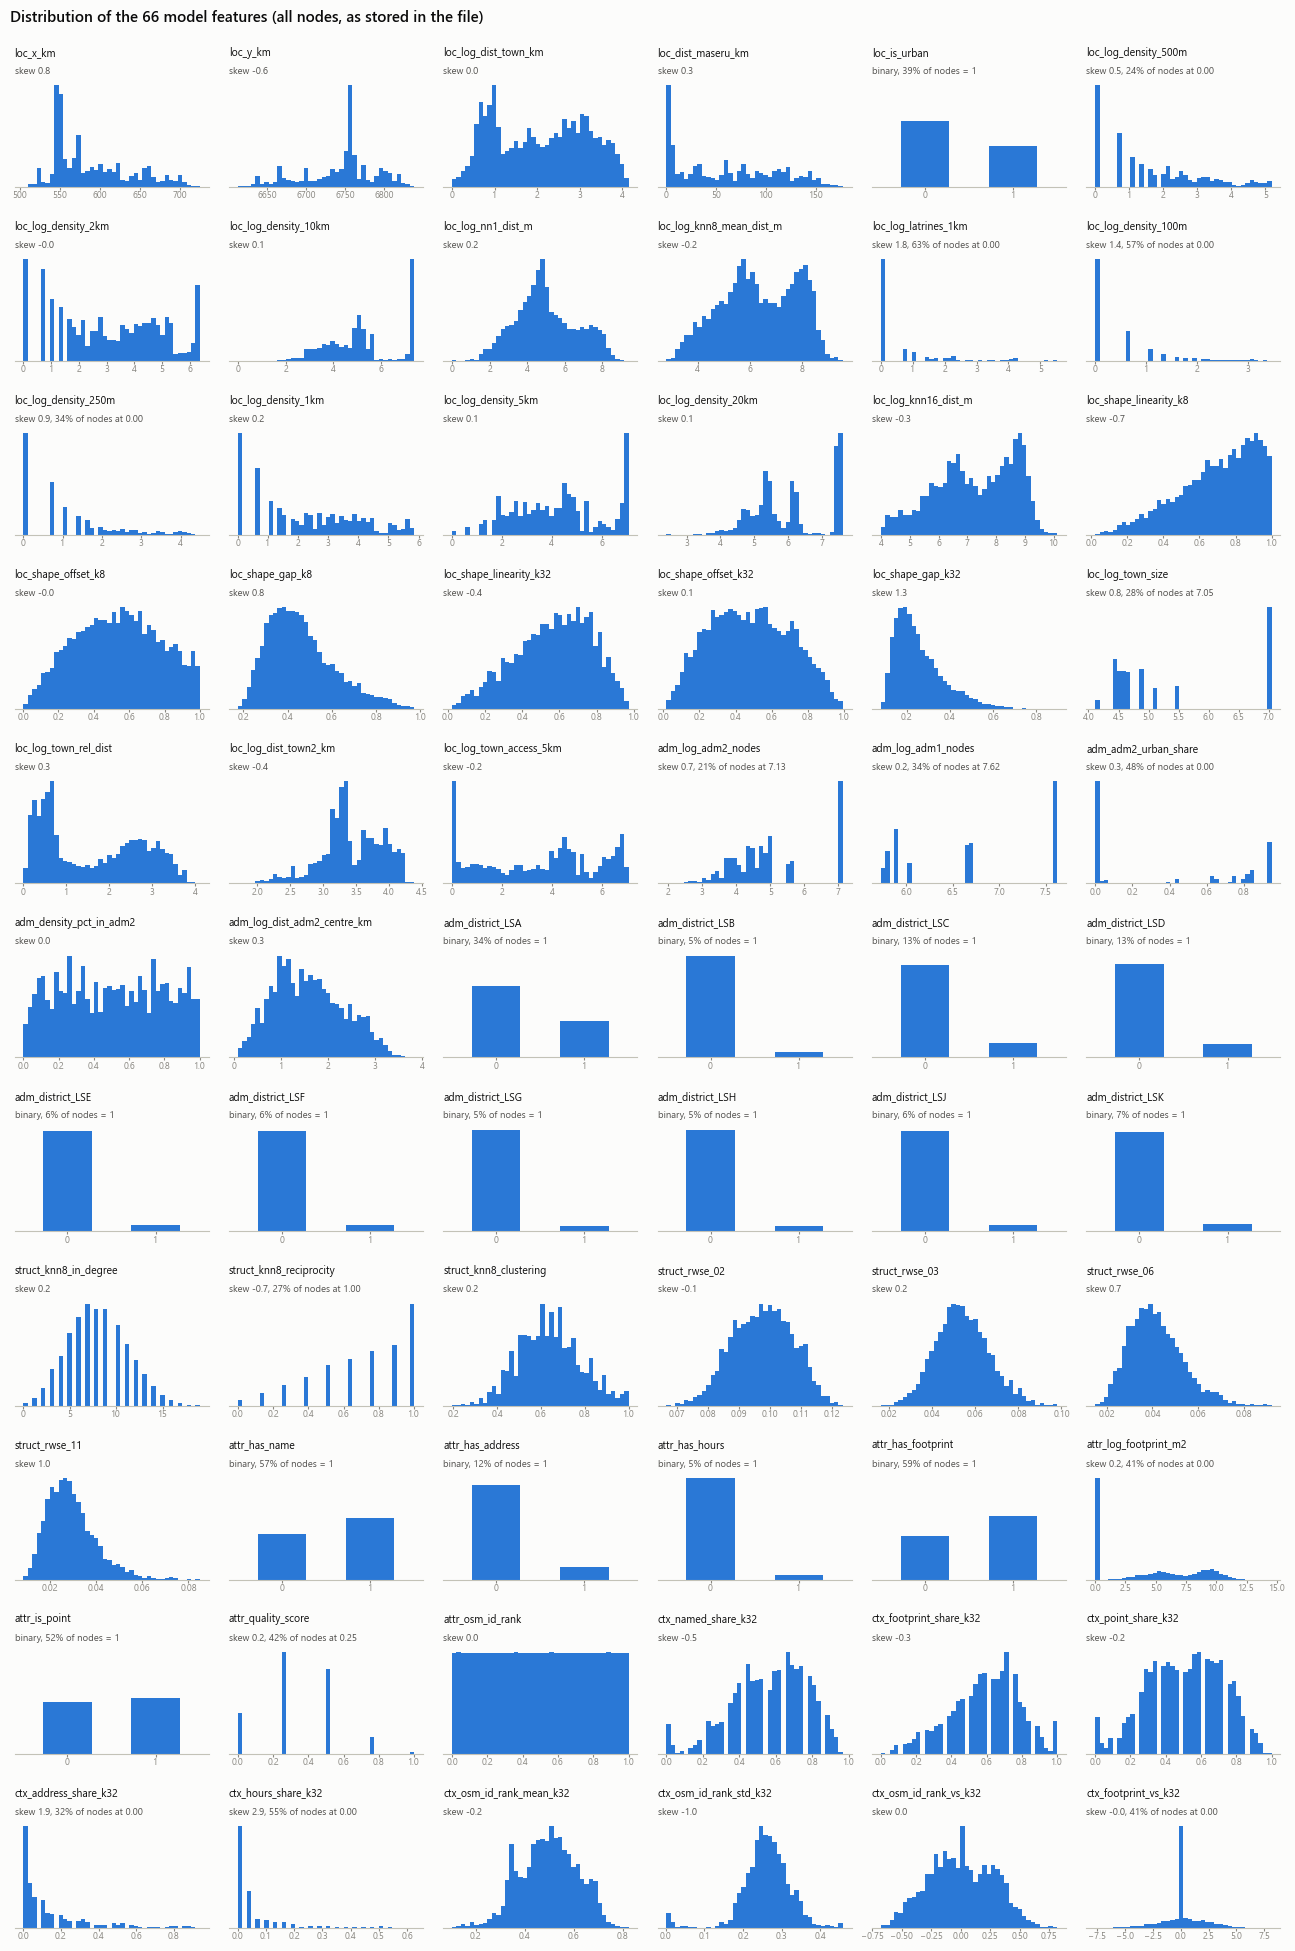

Binary features: 16 | continuous: 50
Continuous features with |skew| <= 1: 43 of 50

Continuous features with |skew| > 1 or > 50% of nodes at one value:
                          group   skew  mode_share    min  median    max
loc_log_latrines_1km        loc  1.757       0.633  0.000   0.000  5.529
loc_log_density_100m        loc  1.435       0.573  0.000   0.000  3.466
loc_shape_gap_k32           loc  1.340       0.000  0.081   0.232  0.896
struct_rwse_11           struct  1.047       0.001  0.009   0.028  0.085
ctx_address_share_k32       ctx  1.933       0.316  0.000   0.062  0.938
ctx_hours_share_k32         ctx  2.864       0.554  0.000   0.000  0.625
ctx_osm_id_rank_std_k32     ctx -1.023       0.000  0.002   0.262  0.458

Binary features, share of nodes = 1:
loc_is_urban          0.385
adm_district_LSA      0.336
adm_district_LSB      0.053
adm_district_LSC      0.133
adm_district_LSD      0.127
adm_district_LSE      0.060
adm_district_LSF      0.058
adm_district_LSG      0.054
a

In [2]:
X = df[FEATS].astype(float)
atlas = pd.DataFrame({
    "group": [group_of[c] for c in FEATS],
    "skew": X.skew(),
    "mode_share": X.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "n_unique": X.nunique(),
    "min": X.min(), "median": X.median(), "max": X.max(),
})
binary = atlas.index[atlas["n_unique"] <= 2].tolist()

NCOL = 6
nrow = int(np.ceil(len(FEATS) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(13, 1.75 * nrow + 0.6))
for ax, c in zip(axes.ravel(), FEATS):
    v = X[c].to_numpy()
    if c in binary:
        share1 = (v == v.max()).mean()
        ax.bar([0, 1], [1 - share1, share1], width=0.55, color=BLUE)
        ax.set_xticks([0, 1]); ax.set_xlim(-0.6, 1.6); ax.set_ylim(0, 1)
        note = f"binary, {share1:.0%} of nodes = 1"
    else:
        ax.hist(v, bins=40, color=BLUE, lw=0)
        note = f"skew {atlas.loc[c, 'skew']:.1f}"
        if atlas.loc[c, "mode_share"] >= 0.2:
            note += f", {atlas.loc[c, 'mode_share']:.0%} of nodes at {pd.Series(v).mode()[0]:.2f}"
    ax.text(0, 1.2, c, transform=ax.transAxes, fontsize=7.6, color=INK, va="bottom")
    ax.text(0, 1.04, note, transform=ax.transAxes, fontsize=6.8, color=INK2, va="bottom")
    ax.set_yticks([]); ax.tick_params(axis="x", labelsize=6.5, length=2, pad=1)
    ax.grid(False); ax.spines["left"].set_visible(False)
for ax in axes.ravel()[len(FEATS):]:
    ax.set_visible(False)
fig.suptitle("Distribution of the 66 model features (all nodes, as stored in the file)", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
plt.tight_layout(rect=(0, 0, 1, 0.985), h_pad=1.4, w_pad=0.8); plt.show()

cont = atlas.drop(index=binary)
print(f"Binary features: {len(binary)} | continuous: {len(cont)}")
print(f"Continuous features with |skew| <= 1: {(cont['skew'].abs() <= 1).sum()} of {len(cont)}")
print("\nContinuous features with |skew| > 1 or > 50% of nodes at one value:")
print(cont[(cont["skew"].abs() > 1) | (cont["mode_share"] > 0.5)]
      [["group", "skew", "mode_share", "min", "median", "max"]].round(3).to_string())
print("\nBinary features, share of nodes = 1:")
print((X[binary].mean()).round(3).to_string())

**Findings.**

- **The features are well-conditioned for a scaler.** 43 of the 50 continuous features have |skew| ≤ 1. Of the other 7,
  four are zero-inflated counts or shares (`loc_log_latrines_1km` 63% zeros, `loc_log_density_100m` 57%,
  `ctx_hours_share_k32` 55%, `ctx_address_share_k32` 32%): a log cannot remove a spike at zero, and the spike is real
  (most nodes have no other POI within 100 m). None has a tail long enough to dominate a neighbour average.
- **Spikes mark shared values, not errors.** The wide-radius counts (`loc_log_density_5km` to `_20km`) and
  `loc_log_town_size` pile up at their maximum because every node in and around Maseru has the same large count
  (28% of nodes have Maseru as their nearest town). The `adm_` features take one value per sub-district or district
  (34% of nodes share Maseru district's `adm_log_adm1_nodes`). Within Maseru these columns are constant, so they act
  as area identifiers there, not as node descriptors.
- **Town versus countryside shows as two peaks.** `loc_log_knn8_mean_dist_m`, `loc_log_knn16_dist_m` and
  `loc_log_town_rel_dist` are bimodal: one peak for nodes inside a town radius, one for rural nodes. A GNN sees both
  regimes through the same weights, which is one reason to keep `loc_is_urban` as an explicit input.
- **Zero sometimes means "missing".** `attr_log_footprint_m2` and `ctx_footprint_vs_k32` are 0 for the 41% of nodes
  without an outline, not because the outline is small. `attr_has_footprint` is in the file to tell the two apart.
- `attr_osm_id_rank` is flat by construction (it is a percentile).

## 2. Feature profile of each category

For the 5,952 labelled nodes, each feature is standardised (mean 0, SD 1 over the labelled nodes, for display only),
and the heatmap shows each category's **mean standardised value**: blue where the category sits above the average
node, red where it sits below. The bar next to it is the **Kruskal–Wallis ε²** of the feature against the 8
categories, the share of the feature's rank variance that the category explains (0 = no difference between the
categories, 1 = the category fixes the value). ε² is rank-based, so it is not driven by tails. Rows are grouped by
prefix and sorted by ε² within each group.

This uses every fold's labels, so like the mutual-information chart in the feature notebook it is descriptive and
is not used to choose features.

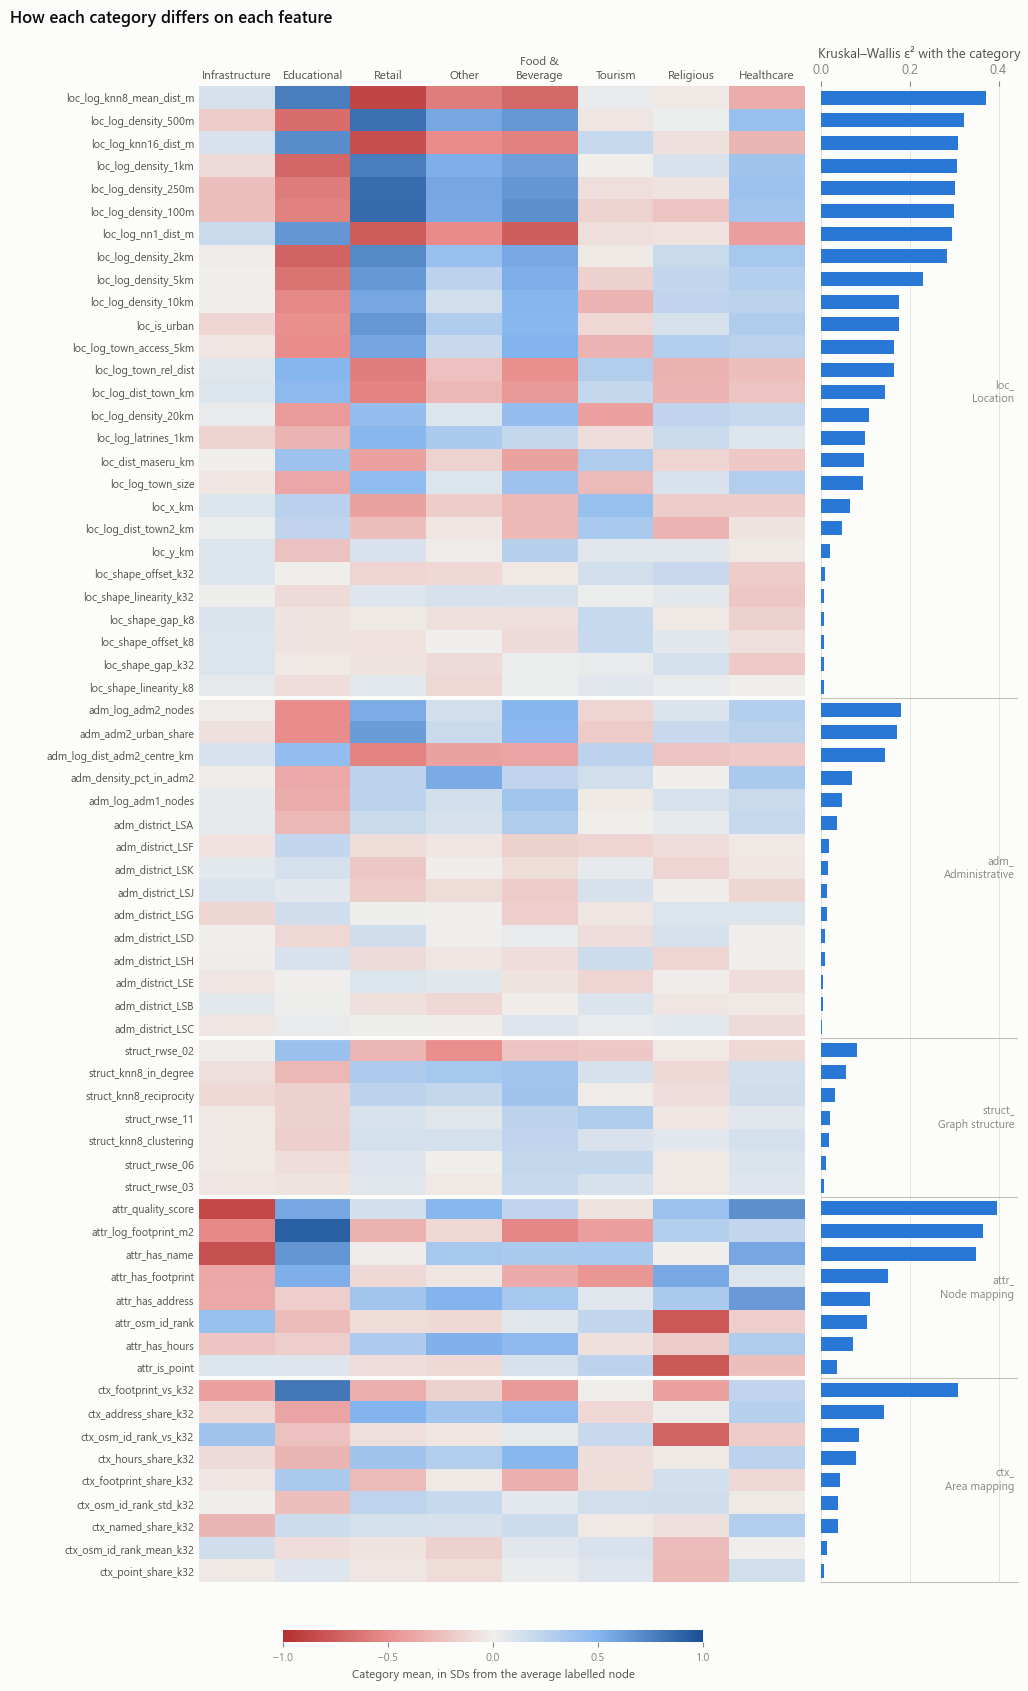

Largest |category mean|: 0.91 SD; cells beyond ±1.0 SD (would be clipped): 0 of 528

Top 12 features by epsilon^2:
attr_quality_score          0.396
loc_log_knn8_mean_dist_m    0.372
attr_log_footprint_m2       0.365
attr_has_name               0.349
loc_log_density_500m        0.321
loc_log_knn16_dist_m        0.310
ctx_footprint_vs_k32        0.309
loc_log_density_1km         0.308
loc_log_density_250m        0.302
loc_log_density_100m        0.299
loc_log_nn1_dist_m          0.296
loc_log_density_2km         0.285

Mean epsilon^2 per group: {'loc': 0.153, 'adm': 0.049, 'struct': 0.032, 'attr': 0.198, 'ctx': 0.084}

Each category's signature (largest mean SDs above / below the average labelled node):
  Infrastructure   above: attr_osm_id_rank +0.41, ctx_osm_id_rank_vs_k32 +0.37, loc_log_nn1_dist_m +0.18
                   below: attr_quality_score -0.87, attr_has_name -0.82
  Educational      above: attr_log_footprint_m2 +0.91, ctx_footprint_vs_k32 +0.80, loc_log_knn8_mean_dist_m +0.

In [3]:
XL = df.loc[lab, FEATS].astype(float)
yl = y[lab]
ZL = (XL - XL.mean()) / XL.std()                      # display only
profile = ZL.groupby(df.loc[lab, "category"]).mean().loc[CATS].T      # features x categories


def epsilon2(v, labels):
    """Kruskal-Wallis epsilon^2 = H / (n - 1): share of rank variance explained by the groups."""
    H = stats.kruskal(*[v[labels == k] for k in np.unique(labels)]).statistic
    return H / (len(v) - 1)


eps = pd.Series({c: epsilon2(XL[c].to_numpy(), yl) for c in FEATS})
order = sorted(FEATS, key=lambda c: (GROUPS.index(group_of[c]), -eps[c]))
P = profile.loc[order]

VMAX = 1.0
fig, (ax, axb) = plt.subplots(1, 2, figsize=(10.5, 17), sharey=True, gridspec_kw={"width_ratios": [8, 2.6],
                                                                                      "wspace": 0.04})
im = ax.imshow(P.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -VMAX, VMAX), aspect="auto")
ax.set_xticks(range(len(CATS)), [c.replace(" & ", " &\n") for c in CATS], fontsize=8.5, color=INK2)
ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0)
ax.set_yticks(range(len(order)), order, fontsize=7.8, color=INK2); ax.tick_params(axis="y", length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

axb.barh(range(len(order)), eps[order], color=BLUE, height=0.62)
axb.set_xlabel("Kruskal–Wallis ε² with the category"); axb.xaxis.set_label_position("top"); axb.xaxis.tick_top()
axb.grid(axis="y", visible=False); axb.tick_params(axis="y", length=0)
axb.spines["left"].set_visible(False)
axb.set_xlim(0, eps.max() * 1.12)

# group separators and labels
bounds = np.flatnonzero(np.diff([GROUPS.index(group_of[c]) for c in order])) + 0.5
for b in bounds:
    ax.axhline(b, color=SURFACE, lw=3)
    axb.axhline(b, color=AXIS, lw=0.8)
starts = np.r_[-0.5, bounds]
ends = np.r_[bounds, len(order) - 0.5]
for g, s0, s1 in zip(GROUPS, starts, ends):
    axb.text(eps.max() * 1.1, (s0 + s1) / 2, f"{g}_\n{GROUP_NAMES[g]}", ha="right", va="center", fontsize=8,
             color=MUTED)
ax.set_ylim(len(order) - 0.5, -0.5)

fig.subplots_adjust(top=0.945, bottom=0.065, left=0.2, right=0.98)
cax = fig.add_axes([0.28, 0.03, 0.4, 0.007])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[-1, -0.5, 0, 0.5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
cb.set_label("Category mean, in SDs from the average labelled node", fontsize=8.5, color=INK2)
fig.suptitle("How each category differs on each feature", x=0.02, y=0.99, ha="left", fontsize=12,
             fontweight="semibold")
plt.show()

print(f"Largest |category mean|: {P.abs().max().max():.2f} SD; cells beyond ±{VMAX} SD (would be clipped): "
      f"{(P.abs() > VMAX).sum().sum()} of {P.size}\n")
print("Top 12 features by epsilon^2:")
print(eps.sort_values(ascending=False).head(12).round(3).to_string())
print("\nMean epsilon^2 per group:", eps.groupby(group_of).mean().reindex(GROUPS).round(3).to_dict())
print("\nEach category's signature (largest mean SDs above / below the average labelled node):")
for cat in CATS:
    s = P[cat].sort_values()
    hi = ", ".join(f"{c} {v:+.2f}" for c, v in s.iloc[::-1][:3].items())
    lo = ", ".join(f"{c} {v:+.2f}" for c, v in s.iloc[:2].items())
    print(f"  {cat:<16} above: {hi}\n  {'':<16} below: {lo}")

**Findings.**

- **Two feature families do most of the separating: local density and spacing (`loc_`), and how the node itself was
  mapped (`attr_`).** 26 features reach ε² ≥ 0.1. The strongest are the node's own mapping completeness
  (`attr_quality_score`, 0.40), spacing to its 8 nearest (`loc_log_knn8_mean_dist_m`, 0.37), outline size
  (`attr_log_footprint_m2`, 0.37) and the density counts at 100 m to 2 km (about 0.3 each). The mean ε² by group is
  0.20 for `attr_`, 0.15 `loc_`, 0.08 `ctx_`, 0.05 `adm_` and 0.03 `struct_`.
- **The categories fall into a few profiles:**
  - *Dense-cluster types*: Retail, Food & Beverage and Other are all above average on density and below average on
    spacing. They share the direction and differ mainly in how strongly (Retail most), so the node features alone
    will confuse these three. Their co-location (EDA Section 6) is the same fact seen from the graph.
  - *Educational* is the mirror image: sparse surroundings, a large outline, and larger than the outlines around it
    (`ctx_footprint_vs_k32` +0.80). It is the most distinct profile.
  - *Infrastructure* is defined by how it was mapped, not where it is: unnamed and incomplete
    (`attr_quality_score` −0.87, `attr_has_name` −0.82), with location features near average.
  - *Religious* is mapped as outlines and early (`attr_is_point` −0.78, `attr_osm_id_rank` −0.79).
  - *Healthcare* is well described (name, address) and slightly denser than average.
  - *Tourism* has the weakest profile: no feature moves its mean by more than 0.46 SD. It will depend most on
    what the graph adds.
- **Neighbourhood shape, graph-structure and district features carry almost no category signal on their own.**
  13 features have ε² below 0.01, among them all six `loc_shape_*` features and most district indicators. The feature
  notebook kept them for what they add in combination and through message passing; the model notebook can test
  that with group ablations.
- **`attr_osm_id_rank` ranks only 26th of 66 here (ε² 0.10), yet it had the highest mutual information in the feature
  notebook (0.46 nats).** ε² measures a shift in the middle of the distribution. The id rank's signal is not a
  simple shift: it comes from the split between point ids and outline ids (Section 8), which mutual information
  picks up and a rank test does not.

## 3. How much the categories overlap on the strongest features

A mean difference in Section 2 can hide heavy overlap. The panels below show the full spread per category for eight
continuous features chosen by ε², skipping any feature whose Spearman |ρ| with one already chosen is 0.7 or more, so
the eight are not eight versions of "density". Boxes span the 25th to 75th percentile, the line inside is the
median, and whiskers reach the 5th and 95th percentiles. The grey vertical line is the median over all labelled
nodes. Log features are shown back on their original scale (counts, metres, m²) so the axes read in real units.

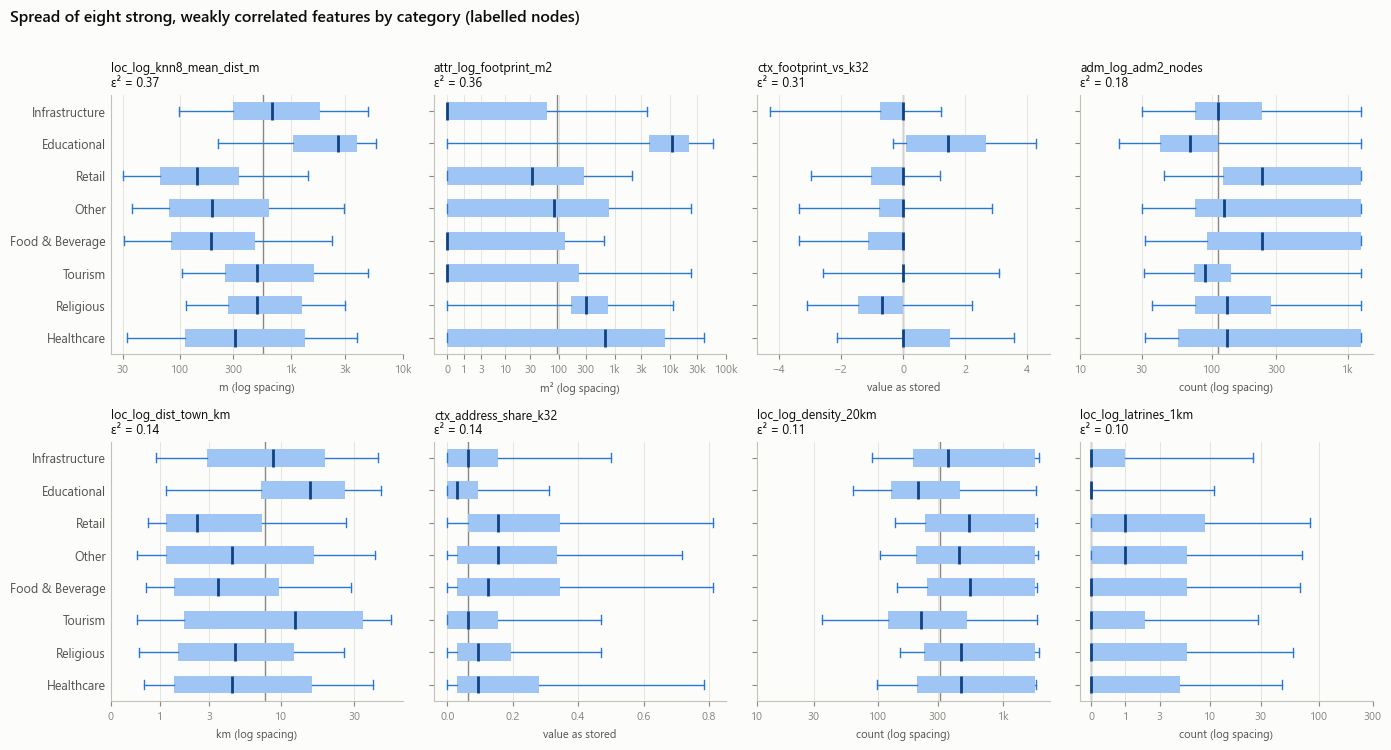

Chosen: ['loc_log_knn8_mean_dist_m', 'attr_log_footprint_m2', 'ctx_footprint_vs_k32', 'adm_log_adm2_nodes', 'loc_log_dist_town_km', 'ctx_address_share_k32', 'loc_log_density_20km', 'loc_log_latrines_1km']

Median per category (original scale):
                          Infrastructure  Educational  Retail   Other  Food & Beverage  Tourism  Religious  Healthcare
loc_log_knn8_mean_dist_m          669.20      2626.05  141.10  195.90           190.40   489.65     491.58      310.38
attr_log_footprint_m2               0.00     10695.27   31.76   80.21             0.00     0.00     304.91      683.71
ctx_footprint_vs_k32                0.00         1.43    0.00    0.00             0.00     0.00      -0.67        0.00
adm_log_adm2_nodes                112.00        69.00  237.00  124.00           237.00    89.00     129.00      129.00
loc_log_dist_town_km                8.95        15.58    2.39    4.53             3.55    12.55       4.80        4.51
ctx_address_share_k32               0.06  

In [4]:
rho_all = XL.rank().corr().abs()          # Spearman, labelled nodes
continuous = [c for c in FEATS if XL[c].nunique() > 10]
picked = []
for c in eps[continuous].sort_values(ascending=False).index:
    if all(rho_all.loc[c, p] < 0.7 for p in picked):
        picked.append(c)
    if len(picked) == 8:
        break

LIGHT_BLUE = "#9ec5f4"
NICE = np.array([0, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000])


def unit_of(col):
    if "_log_" not in col:
        return None
    return "m²" if col.endswith("_m2") else "m" if col.endswith("_m") else "km" if col.endswith("_km") else "count"


def real_ticks(ax, v):
    """Keep the stored log1p scale, but label ticks in original units."""
    t = NICE[(np.log1p(NICE) >= v.min() - 1e-9) & (np.log1p(NICE) <= v.max() + 0.3)]
    ax.set_xticks(np.log1p(t), [f"{x / 1000:g}k" if x >= 1000 else f"{x:g}" for x in t])


fig, axes = plt.subplots(2, 4, figsize=(14, 7.6), sharey=True)
for ax, c in zip(axes.ravel(), picked):
    vals = XL[c].to_numpy()
    groups = [vals[yl == k] for k in range(len(CATS))]
    ax.bxp([{"med": np.median(g), "q1": np.percentile(g, 25), "q3": np.percentile(g, 75),
             "whislo": np.percentile(g, 5), "whishi": np.percentile(g, 95), "fliers": []} for g in groups],
           positions=range(len(CATS)), vert=False, widths=0.55, patch_artist=True, showfliers=False,
           boxprops={"facecolor": LIGHT_BLUE, "edgecolor": "none"},
           medianprops={"color": "#104281", "lw": 2}, whiskerprops={"color": BLUE, "lw": 1},
           capprops={"color": BLUE, "lw": 1})
    ax.axvline(np.median(vals), color=MUTED, lw=1, zorder=0)
    unit = unit_of(c)
    if unit:
        real_ticks(ax, vals)
    ax.set_title(f"{c}\nε² = {eps[c]:.2f}", fontsize=9, fontweight="normal", loc="left")
    ax.set_xlabel(f"{unit} (log spacing)" if unit else "value as stored", fontsize=8)
    ax.grid(axis="y", visible=False); ax.tick_params(labelsize=8)
axes[0, 0].set_yticks(range(len(CATS)), CATS); axes[0, 0].invert_yaxis()
for ax in axes[:, 0]:
    ax.tick_params(axis="y", labelsize=9, colors=INK2, length=0)
fig.suptitle("Spread of eight strong, weakly correlated features by category (labelled nodes)", x=0.01, ha="left",
             fontsize=11.5, fontweight="semibold")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

print("Chosen:", picked)
print("\nMedian per category (original scale):")
med = pd.DataFrame({c: XL[c].groupby(yl).median().pipe(np.expm1 if unit_of(c) else lambda s: s).to_numpy()
                    for c in picked}, index=CATS)
print(med.round(2).T.to_string())

**Findings.**

- **Overlap is heavy even on the strongest features.** For every feature, the middle halves (boxes) of most
  category pairs overlap. No single feature, and no pair of them, can classify the nodes; the signal is spread
  thinly over many features, which suits a model that combines them.
- **Educational is the only category set apart on its own features.** Its median spacing to the 8 nearest is 2.6 km
  against 140 m for Retail; its median outline is about 10,700 m² (school compounds are mapped as site outlines) and
  about 4 times the outlines around it (`ctx_footprint_vs_k32` median +1.43 on the log scale).
- **Retail, Other and Food & Beverage are nearly indistinguishable here.** Their boxes overlap on all eight features,
  confirming the shared dense-cluster profile of Section 2. Telling them apart will need what the graph adds, such as
  the categories of neighbouring nodes, learned inside each training fold.
- **Infrastructure and Tourism spread across the whole range** (wide boxes on spacing and distance to town): both mix
  urban and remote places (a mast on a hill and a car park in town; a lodge in the mountains and a guest house in
  Maseru).
- **Religious nodes are outlined but smaller than the outlines around them** (median −0.67, about half the
  neighbours' size): churches traced among larger compounds.
- `adm_log_adm2_nodes` reaches its ceiling for Retail and Food & Beverage (their upper quartile is the largest
  sub-district, in Maseru); it works as an "is this Maseru's commercial sub-district" flag more than as a count.

## 4. Redundancy between the features

The feature notebook dropped any feature with Spearman |ρ| ≥ 0.95 against one already kept. Below that threshold,
features can still overlap a lot. The heatmap shows the Spearman correlation between all 66 features over all 6,083
nodes (no labels are used), grouped by prefix and ordered within each group by hierarchical clustering so related
features sit together. The right panel is a principal-component scree of the standardised features: how many
independent directions the 66 columns actually span.

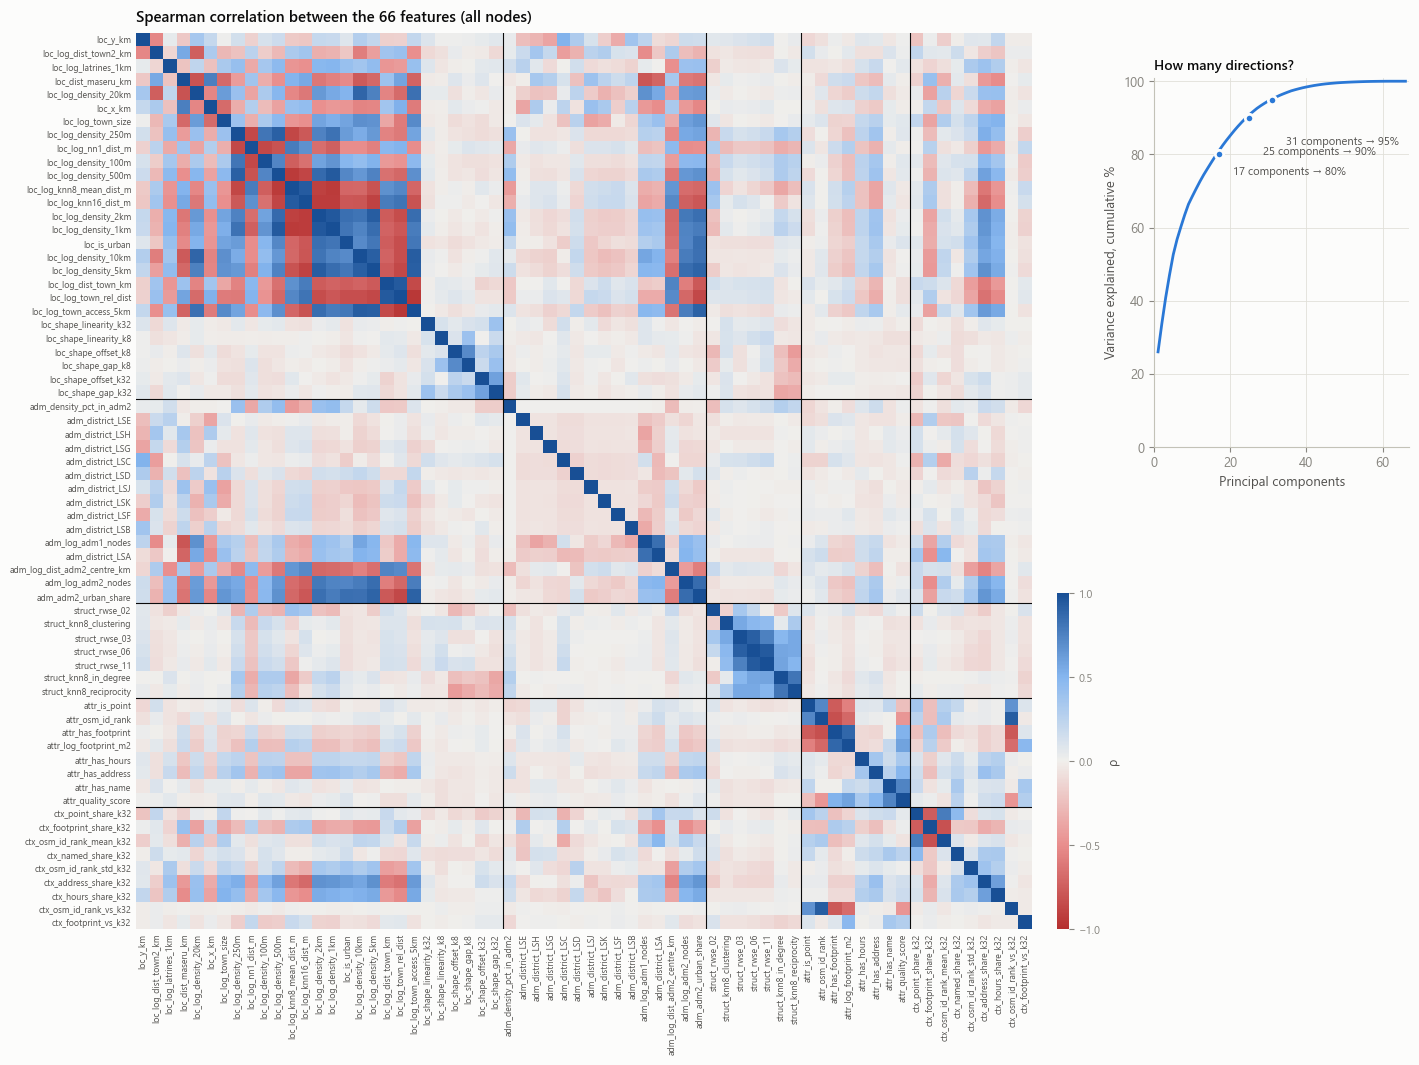

Principal components for 80 / 90 / 95% of the variance: 17 / 25 / 31 of 66
Feature pairs with |rho| >= 0.9: 18 | >= 0.8: 58 | >= 0.5: 235 of 2145

Strongest pairs across different groups:
                      a                      b    rho
       attr_osm_id_rank ctx_osm_id_rank_vs_k32  0.925
loc_log_town_access_5km   adm_adm2_urban_share  0.898
    loc_log_density_5km   adm_adm2_urban_share  0.895
  loc_log_town_rel_dist   adm_adm2_urban_share -0.860
    loc_log_density_5km     adm_log_adm2_nodes  0.846
    loc_log_density_2km   adm_adm2_urban_share  0.843
           loc_is_urban   adm_adm2_urban_share  0.842
   loc_log_density_10km   adm_adm2_urban_share  0.832

Mean |rho| within and between groups:
         loc   adm  struct  attr   ctx
loc     0.37  0.22    0.11  0.10  0.17
adm     0.22  0.14    0.05  0.07  0.13
struct  0.11  0.05    0.45  0.04  0.05
attr    0.10  0.07    0.04  0.35  0.18
ctx     0.17  0.13    0.05  0.18  0.19


In [5]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

rho = X.rank().corr()                                 # Spearman over all nodes


def cluster_order(cols):
    if len(cols) < 3:
        return cols
    d = 1 - rho.loc[cols, cols].abs().to_numpy()
    np.fill_diagonal(d, 0)
    return [cols[i] for i in leaves_list(linkage(squareform(d, checks=False), "average"))]


corder = [c for g in GROUPS for c in cluster_order([c for c in FEATS if group_of[c] == g])]
R = rho.loc[corder, corder]

Zall = ((X - X.mean()) / X.std()).to_numpy()
ev = np.linalg.eigvalsh(np.cov(Zall, rowvar=False))[::-1]
cum = np.cumsum(ev) / ev.sum()
n80, n90, n95 = [int(np.searchsorted(cum, q) + 1) for q in (0.8, 0.9, 0.95)]

fig = plt.figure(figsize=(15, 11.2))
ax = fig.add_axes([0.13, 0.12, 0.6, 0.8])
im = ax.imshow(R.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -1, 1))
ax.set_xticks(range(len(corder)), corder, rotation=90, fontsize=6.4, color=INK2)
ax.set_yticks(range(len(corder)), corder, fontsize=6.4, color=INK2)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
gb = np.flatnonzero(np.diff([GROUPS.index(group_of[c]) for c in corder])) + 0.5
for b in gb:
    ax.axhline(b, color=INK, lw=0.8); ax.axvline(b, color=INK, lw=0.8)
ax.set_title("Spearman correlation between the 66 features (all nodes)", pad=8)
cax = fig.add_axes([0.745, 0.12, 0.008, 0.3])
cb = fig.colorbar(im, cax=cax, ticks=[-1, -0.5, 0, 0.5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8); cb.set_label("ρ", fontsize=9, color=INK2)

axs = fig.add_axes([0.81, 0.55, 0.17, 0.33])
k = np.arange(1, len(ev) + 1)
axs.plot(k, cum * 100, color=BLUE, lw=2)
for n, q in [(n80, 80), (n90, 90), (n95, 95)]:
    axs.plot(n, q, "o", color=BLUE, ms=6, mec=SURFACE, mew=2)
    axs.annotate(f"{n} components → {q}%", (n, q), xytext=(10, -8 - (q - 80) * 1.2), textcoords="offset points",
                 fontsize=8, color=INK2, va="top")
axs.set_xlabel("Principal components"); axs.set_ylabel("Variance explained, cumulative %")
axs.set_ylim(0, 101); axs.set_xlim(0, len(ev) + 1)
axs.set_title("How many directions?", fontsize=10)
plt.show()

iu = np.triu_indices(len(FEATS), 1)
pairs = pd.DataFrame({"a": np.array(FEATS)[iu[0]], "b": np.array(FEATS)[iu[1]],
                      "rho": rho.loc[FEATS, FEATS].to_numpy()[iu]})
pairs["abs"] = pairs["rho"].abs()
print(f"Principal components for 80 / 90 / 95% of the variance: {n80} / {n90} / {n95} of {len(FEATS)}")
print(f"Feature pairs with |rho| >= 0.9: {(pairs['abs'] >= 0.9).sum()} | >= 0.8: {(pairs['abs'] >= 0.8).sum()} | "
      f">= 0.5: {(pairs['abs'] >= 0.5).sum()} of {len(pairs)}")
print("\nStrongest pairs across different groups:")
cross = pairs[[group_of[a] != group_of[b] for a, b in zip(pairs["a"], pairs["b"])]]
print(cross.sort_values("abs", ascending=False).head(8)[["a", "b", "rho"]].round(3).to_string(index=False))
print("\nMean |rho| within and between groups:")
G = pd.DataFrame(index=GROUPS, columns=GROUPS, dtype=float)
for g1 in GROUPS:
    for g2 in GROUPS:
        c1 = [c for c in FEATS if group_of[c] == g1]; c2 = [c for c in FEATS if group_of[c] == g2]
        m = rho.loc[c1, c2].abs().to_numpy()
        G.loc[g1, g2] = m[~np.eye(len(c1), dtype=bool)].mean() if g1 == g2 else m.mean()
print(G.round(2).to_string())

**Findings.**

- **The 66 columns span about 25 independent directions** (17 principal components hold 80% of the variance, 25
  hold 90%, 31 hold 95%). The redundancy is harmless for a GNN, whose first linear layer mixes the inputs anyway, but
  it matters when reading feature importance: credit is split across correlated features.
- **One large block is "how urban is this place".** About 20 `loc_` density, spacing and town features correlate
  strongly with each other (50 of the file's 58 pairs with |ρ| ≥ 0.8 lie in this block), and the sub-district features `adm_adm2_urban_share`,
  `adm_log_adm2_nodes` and `adm_log_dist_adm2_centre_km` belong to the same block (|ρ| up to 0.90 with
  `loc_log_town_access_5km`). They are the same urban–rural gradient at the node and at the sub-district scale.
- **Neighbourhood shape and graph structure are almost independent of everything else** (mean |ρ| with other groups
  0.04 to 0.11). They carry little category signal on their own (Section 2), but what they carry is new. Inside
  `struct_`, the random-walk steps 3, 6 and 11 and the in-degree form one tight cluster; `struct_rwse_02` and the
  clustering coefficient stand apart.
- **The mapping features form their own block.** `attr_osm_id_rank` correlates with `attr_is_point` (positive) and
  `attr_has_footprint` (negative), as the ReadMe caveat describes, and at ρ = 0.93 with `ctx_osm_id_rank_vs_k32`, just
  under the 0.95 drop threshold. The three `osm_id_rank` columns are close to one signal, so removing them for the
  mapping-bias check removes that signal cleanly.
- The district indicators are independent of each other and of most features, apart from Maseru (`adm_district_LSA`)
  and the district size `adm_log_adm1_nodes`.

## 5. The features on the k = 8 graph

A GNN layer replaces each node's features with a mix of its own and its neighbours' average. Two properties of a
feature decide what that does:

- **Smoothness**: the correlation between a node's value and the mean value of its graph neighbours. A smooth feature
  (r near 1) barely changes when averaged, so message passing adds little to it; a rough feature (r near 0) is
  node-specific and gets diluted by averaging.
- **Signal after averaging**: the Kruskal–Wallis ε² of the neighbour mean against the node's own category, next to
  the ε² of the node's own value (Section 2). Where the neighbour mean is stronger, a node's surroundings say more
  about its category than the node itself does, which is the case for a GNN over a plain per-node model.

The graph is the one the model uses: 8 nearest neighbours from `x_km`/`y_km`, made undirected, self excluded
explicitly (two nodes share a position). The neighbour mean is taken over all nodes, including unlabelled ones;
ε² uses the labelled nodes.

k=8 graph: 31,452 undirected edges, degree 8-20 (median 10); in-degree matches struct_knn8_in_degree


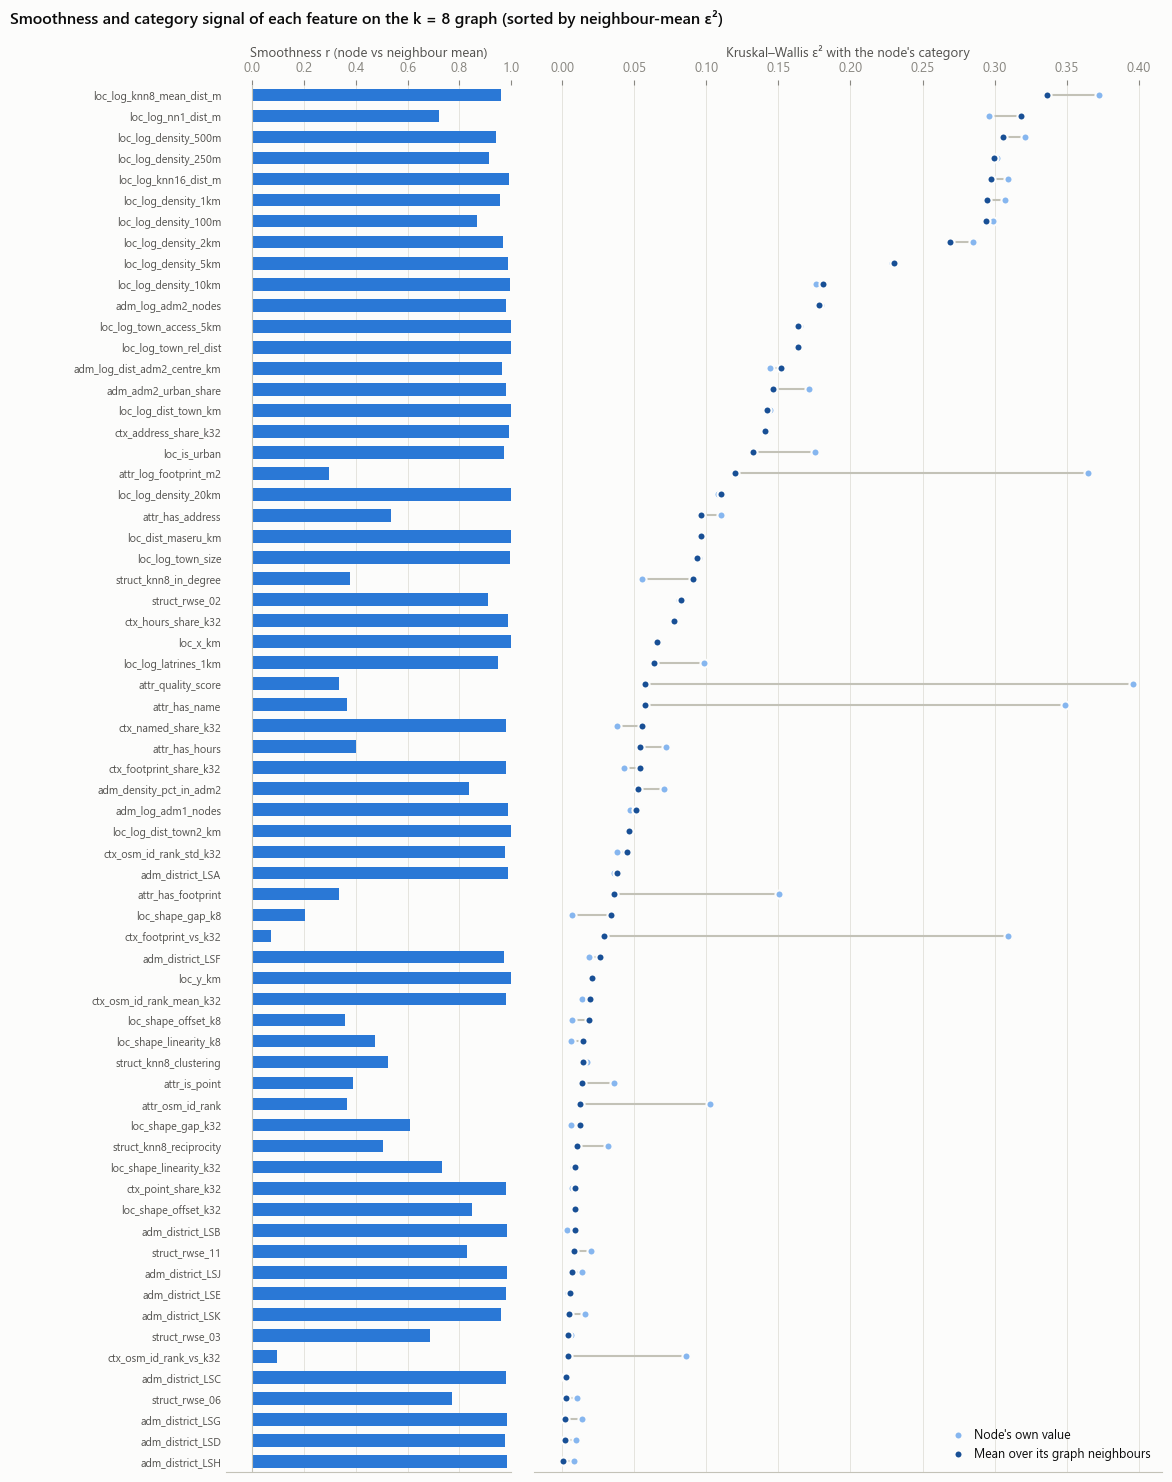

Median smoothness r: 0.97 | features with r >= 0.8: 45 | r < 0.3: 4
Neighbour mean more informative than own value: 27 of 66 features

By group (medians):
        smooth_r  eps_own  eps_nbr   gain
group                                    
loc        0.967    0.144    0.132 -0.000
adm        0.980    0.015    0.009 -0.001
struct     0.685    0.020    0.010 -0.003
attr       0.368    0.130    0.056 -0.102
ctx        0.978    0.043    0.045  0.002

Largest gains from averaging:
                          group  smooth_r  eps_own  eps_nbr   gain
struct_knn8_in_degree    struct     0.380    0.056    0.091  0.035
loc_shape_gap_k8            loc     0.203    0.007    0.034  0.027
loc_log_nn1_dist_m          loc     0.721    0.296    0.319  0.023
ctx_named_share_k32         ctx     0.978    0.038    0.055  0.017
loc_shape_offset_k8         loc     0.358    0.007    0.019  0.012
ctx_footprint_share_k32     ctx     0.978    0.043    0.054  0.011

Largest losses from averaging:
                   

In [6]:
from scipy import sparse
from scipy.sparse.csgraph import connected_components

XY = df[["x_km", "y_km"]].to_numpy() * 1000
# Query 34 neighbours as poi_feature_engineering.ipynb Section 3 does: one node has a distance tie at its 8th
# neighbour, and a shorter query breaks that tie the other way (same edge count, one edge swapped).
_, nn_i = cKDTree(XY).query(XY, k=34)
nn_i = nn_i[nn_i != np.arange(N)[:, None]].reshape(N, 33)[:, :K]          # drop self explicitly
A_dir = sparse.csr_matrix((np.ones(N * K), (np.repeat(np.arange(N), K), nn_i.ravel())), shape=(N, N))
A = ((A_dir + A_dir.T) > 0).astype(float).tocsr()
deg = np.asarray(A.sum(1)).ravel()
assert A.diagonal().sum() == 0 and connected_components(A, directed=False)[0] == 1
assert np.array_equal(np.asarray(A_dir.sum(0)).ravel(), df["struct_knn8_in_degree"].to_numpy()), \
    "graph differs from the one the struct_ features were computed on"
print(f"k={K} graph: {A.nnz // 2:,} undirected edges, degree {deg.min():.0f}-{deg.max():.0f} "
      f"(median {np.median(deg):.0f}); in-degree matches struct_knn8_in_degree")

P_mean = sparse.diags(1 / deg) @ A                           # row-normalised: neighbour mean
Zn = (X - X.mean()) / X.std()
NB = pd.DataFrame(P_mean @ Zn.to_numpy(), columns=FEATS)     # neighbour mean of each standardised feature
smooth = pd.Series({c: np.corrcoef(Zn[c], NB[c])[0, 1] for c in FEATS})
eps_nb = pd.Series({c: epsilon2(NB.loc[lab, c].to_numpy(), yl) for c in FEATS})

gs = pd.DataFrame({"group": pd.Series(group_of), "smooth_r": smooth, "eps_own": eps, "eps_nbr": eps_nb})
gs["gain"] = gs["eps_nbr"] - gs["eps_own"]
order5 = gs.sort_values(["eps_nbr"], ascending=False).index.tolist()

OWN, NBR = "#86b6ef", "#184f95"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 15), sharey=True, gridspec_kw={"width_ratios": [1, 2.2],
                                                                                   "wspace": 0.05})
ypos = np.arange(len(order5))
ax1.barh(ypos, gs.loc[order5, "smooth_r"], color=BLUE, height=0.6)
ax1.axvline(0, color=AXIS, lw=0.8)
ax1.set_xlim(-0.1, 1); ax1.set_xlabel("Smoothness r (node vs neighbour mean)")
ax1.xaxis.set_label_position("top"); ax1.xaxis.tick_top()
ax1.set_yticks(ypos, order5, fontsize=7.8, color=INK2); ax1.tick_params(axis="y", length=0)
ax1.grid(axis="y", visible=False); ax1.spines["left"].set_visible(False)
ax1.set_ylim(len(order5) - 0.5, -0.5)

for yv, c in zip(ypos, order5):
    a, b = gs.loc[c, "eps_own"], gs.loc[c, "eps_nbr"]
    ax2.plot([a, b], [yv, yv], color=AXIS, lw=1.5, zorder=1)
ax2.scatter(gs.loc[order5, "eps_own"], ypos, s=34, color=OWN, edgecolor=SURFACE, lw=1.5, zorder=2,
            label="Node's own value")
ax2.scatter(gs.loc[order5, "eps_nbr"], ypos, s=34, color=NBR, edgecolor=SURFACE, lw=1.5, zorder=3,
            label="Mean over its graph neighbours")
ax2.set_xlabel("Kruskal–Wallis ε² with the node's category"); ax2.xaxis.set_label_position("top")
ax2.xaxis.tick_top(); ax2.grid(axis="y", visible=False); ax2.tick_params(axis="y", length=0)
ax2.spines["left"].set_visible(False)
ax2.legend(loc="lower right", fontsize=9, handletextpad=0.3)
fig.suptitle("Smoothness and category signal of each feature on the k = 8 graph (sorted by neighbour-mean ε²)",
             x=0.02, y=0.995, ha="left", fontsize=11.5, fontweight="semibold")
fig.subplots_adjust(top=0.945, bottom=0.02, left=0.2, right=0.98)
plt.show()

print(f"Median smoothness r: {smooth.median():.2f} | features with r >= 0.8: {(smooth >= 0.8).sum()} | "
      f"r < 0.3: {(smooth < 0.3).sum()}")
print(f"Neighbour mean more informative than own value: {(gs['gain'] > 0).sum()} of {len(FEATS)} features")
print("\nBy group (medians):")
print(gs.groupby("group")[["smooth_r", "eps_own", "eps_nbr", "gain"]].median().reindex(GROUPS).round(3).to_string())
print("\nLargest gains from averaging:")
print(gs.sort_values("gain", ascending=False).head(6).round(3).to_string())
print("\nLargest losses from averaging:")
print(gs.sort_values("gain").head(6).round(3).to_string())

**Findings.**

- **Most features barely change across an edge.** The median smoothness is r = 0.97, and 45 of 66 features have
  r ≥ 0.8. Almost all `loc_`, `adm_` and `ctx_` features describe the area rather than the node, so a node and its
  8 nearest neighbours share nearly the same values. Averaging them adds little to what the node already has.
- **The node's own mapping attributes are the rough ones, and averaging destroys their signal.** The `attr_`
  features have r = 0.30 to 0.54, and the two node-versus-area contrasts are rougher still
  (`ctx_footprint_vs_k32` r = 0.07, `ctx_osm_id_rank_vs_k32` r = 0.10). Averaged over neighbours, their ε² collapses: `attr_quality_score` 0.40 → 0.06,
  `attr_has_name` 0.35 → 0.06, `attr_log_footprint_m2` 0.37 → 0.12, `ctx_footprint_vs_k32` 0.31 → 0.03. These are
  among the most informative features in the file, and a node's own value of them is not predictable from its
  neighbours.
- **Averaging raises the signal only slightly, and only for a few features.** The largest gains are
  `struct_knn8_in_degree` (0.06 → 0.09), `loc_shape_gap_k8` (0.01 → 0.03) and `loc_log_nn1_dist_m` (0.30 → 0.32).
  27 features gain at all; none gains much.
- **What this means for the GNN architecture.** A layer that mixes a node's own features into the neighbour average
  with the same weight (plain GCN, where the node counts as 1 of its 9 to 21 inputs) would dilute exactly the
  features that separate categories best. Layers that keep a **separate weight for the node itself**
  (GraphSAGE, GraphConv with a root weight, or any layer followed by a skip/residual connection) keep that signal
  intact while adding neighbourhood context. Averaged features carry little extra category signal on their own
  (these are one-feature measures; combinations can do more). Section 6 looks at the other thing the graph
  offers: neighbours of the same category.

## 6. Same-category neighbours: on the map versus in feature space

A GNN classifies a node from two sources: its own features, and its graph neighbours. This section asks, per
category, which source puts same-category nodes next to each other:

- **Graph neighbours**: the share of a node's labelled neighbours on the k = 8 graph that share its category
  (label homophily; 38% overall, as in the EDA).
- **Feature-space neighbours**: the share of a node's 8 nearest labelled nodes in the space of the 66 standardised
  features that share its category, which is what a nearest-neighbour classifier on the features would see. The
  feature space includes the coordinates and many area-level features, so feature-space neighbours are often map
  neighbours as well. The measure is therefore given twice: with neighbours from **any fold**, and with
  neighbours from **other folds only**, as a model tested on held-out 5 km blocks would face.
- **Chance**: the category's share of the labelled nodes, the expected value if neighbours were drawn at random.

Descriptive only.

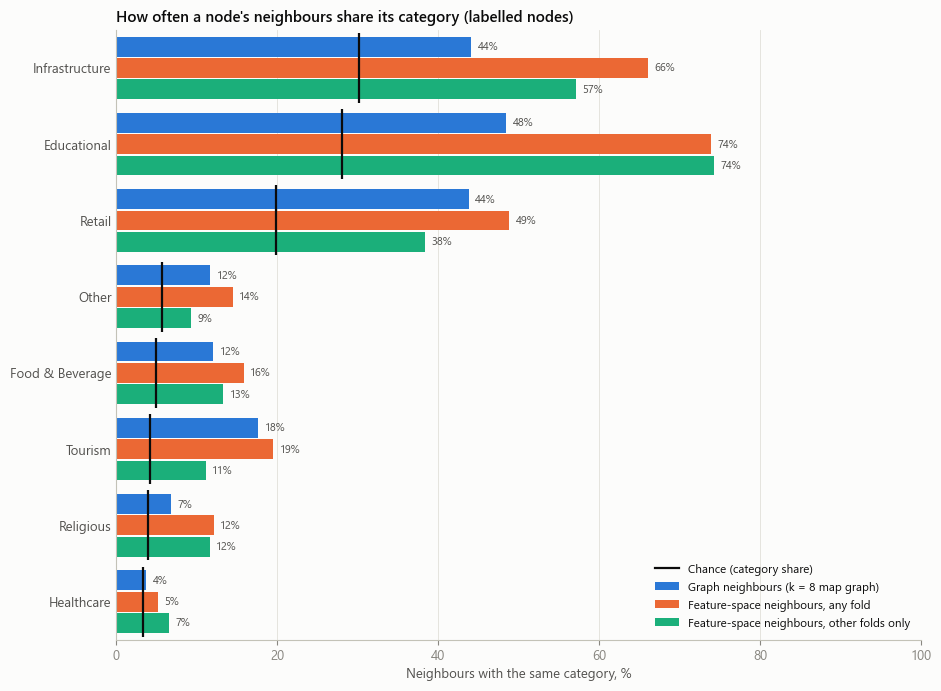

Overall same-category share: graph 37.9% | features, any fold 53.3% | features, other folds 47.9% | two random labelled nodes 21.8%
Feature-space neighbours (any fold): 61% in the node's own fold, median 2.0 km away on the map
Graph edges inside one fold: 77% (so most neighbours of a held-out node are held out too)
Labelled nodes with no labelled graph neighbour: 4

                 graph  features_any_fold  features_other_folds  chance
Infrastructure    44.1               66.1                  57.1    30.1
Educational       48.5               73.9                  74.3    28.0
Retail            43.8               48.8                  38.3    19.8
Other             11.6               14.4                   9.2     5.6
Food & Beverage   12.0               15.8                  13.3     4.9
Tourism           17.6               19.5                  11.1     4.2
Religious          6.7               12.1                  11.6     4.0
Healthcare         3.7                5.1              

In [7]:
li = np.flatnonzero(lab)                                 # labelled node indices
fold = df["fold"].to_numpy()
fl = fold[li]

# Graph homophily: share of each labelled node's labelled graph neighbours with the same category
Al = A[li][:, li].tocsr()
same = np.asarray(Al.multiply(yl[:, None] == yl[None, :]).sum(1)).ravel()
n_lab_nbr = np.asarray(Al.sum(1)).ravel()
has_nbr = n_lab_nbr > 0
graph_same = np.where(has_nbr, same / np.maximum(n_lab_nbr, 1), np.nan)

# Feature-space homophily: 8 nearest labelled nodes in the standardised 66-feature space
ZLn = ZL.to_numpy()
_, fi = cKDTree(ZLn).query(ZLn, k=K + 1)
fi = np.array([row[row != i][:K] for i, row in enumerate(fi)])          # drop self explicitly
feat_same = (yl[fi] == yl[:, None]).mean(1)

# ... and with neighbours restricted to the other four folds
feat_cross = np.zeros(len(li))
for f in range(5):
    q, ref = fl == f, fl != f
    _, j = cKDTree(ZLn[ref]).query(ZLn[q], k=K)
    feat_cross[q] = (yl[ref][j] == yl[q][:, None]).mean(1)

by = lambda v: pd.Series(v).groupby(yl).mean().to_numpy()
hom = pd.DataFrame({"graph": by(graph_same), "features_any_fold": by(feat_same),
                    "features_other_folds": by(feat_cross),
                    "chance": pd.Series(yl).value_counts(normalize=True).sort_index().to_numpy()}, index=CATS)

SERIES = [("graph", BLUE, "Graph neighbours (k = 8 map graph)"),
          ("features_any_fold", ORANGE, "Feature-space neighbours, any fold"),
          ("features_other_folds", AQUA, "Feature-space neighbours, other folds only")]
fig, ax = plt.subplots(figsize=(9.5, 7))
yy = np.arange(len(CATS))
h = 0.26
for s, (col, colr, name) in enumerate(SERIES):
    pos = yy + (s - 1) * (h + 0.02)
    ax.barh(pos, hom[col] * 100, height=h, color=colr, label=name)
    for p, v in zip(pos, hom[col]):
        ax.text(v * 100 + 0.8, p, f"{v:.0%}", va="center", fontsize=7.8, color=INK2)
for yv, c in zip(yy, hom["chance"]):
    ax.plot([c * 100, c * 100], [yv - 0.46, yv + 0.46], color=INK, lw=1.6, solid_capstyle="butt")
ax.plot([], [], color=INK, lw=1.6, label="Chance (category share)")
ax.set_yticks(yy, CATS, color=INK2); ax.tick_params(axis="y", length=0); ax.set_ylim(len(CATS) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Neighbours with the same category, %"); ax.set_xlim(0, 100)
ax.set_title("How often a node's neighbours share its category (labelled nodes)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

Ab = A.tocoo()
d_map = np.hypot(*(XY[li][fi] - XY[li][:, None, :]).transpose(2, 0, 1)) / 1000
print(f"Overall same-category share: graph {np.nanmean(graph_same):.1%} | features, any fold {feat_same.mean():.1%} | "
      f"features, other folds {feat_cross.mean():.1%} | two random labelled nodes "
      f"{(pd.Series(yl).value_counts(normalize=True) ** 2).sum():.1%}")
print(f"Feature-space neighbours (any fold): {(fl[fi] == fl[:, None]).mean():.0%} in the node's own fold, median "
      f"{np.median(d_map):.1f} km away on the map")
print(f"Graph edges inside one fold: {(fold[Ab.row] == fold[Ab.col]).mean():.0%} "
      f"(so most neighbours of a held-out node are held out too)")
print(f"Labelled nodes with no labelled graph neighbour: {(~has_nbr).sum()}\n")
print((hom * 100).round(1).to_string())

### A map of the feature space

t-SNE places the 5,952 labelled nodes in two dimensions so that nodes with similar standardised features land close
together. Distances between far-apart groups in a t-SNE map are not meaningful; what it shows is which categories
form their own regions and which are mixed. One panel per category, that category in blue over all other nodes in grey.

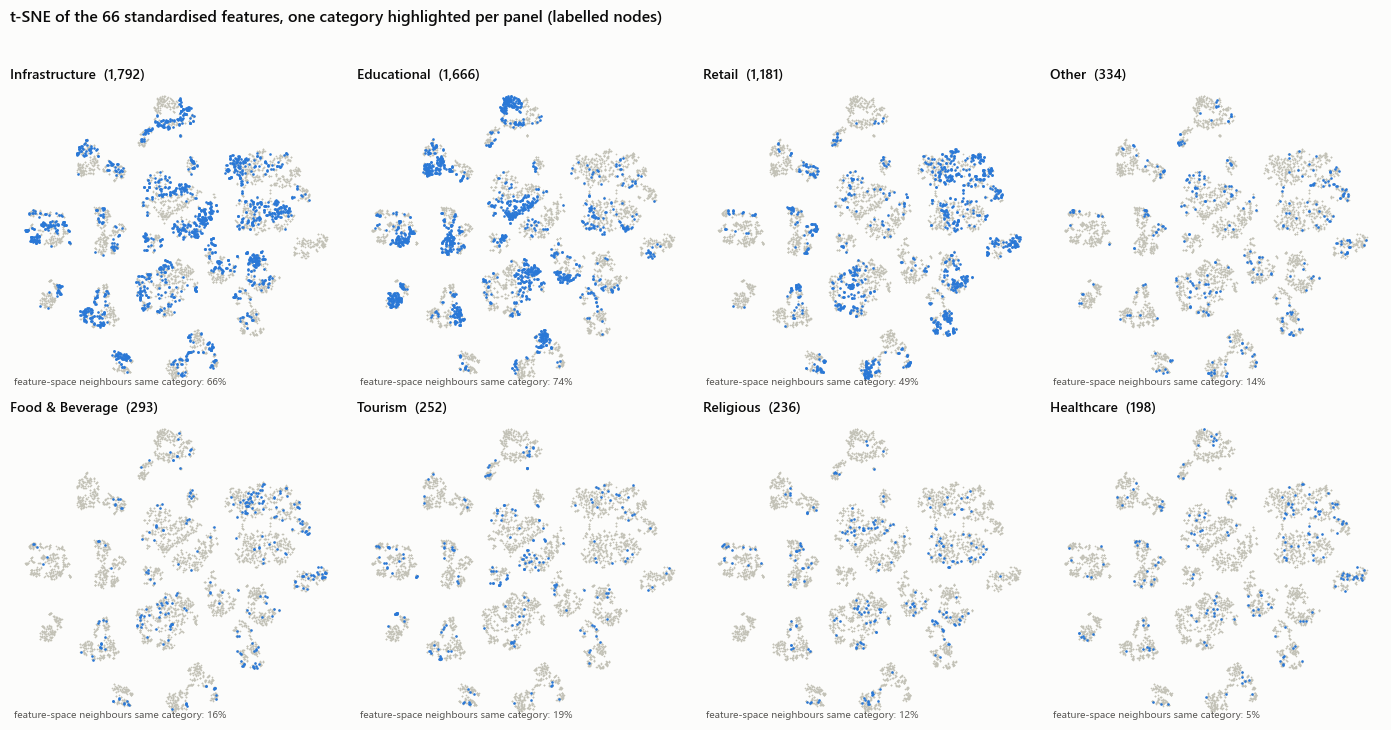

Features most aligned with the two t-SNE axes (|Spearman rho|):
  tsne_1: loc_dist_maseru_km 0.91, loc_log_density_10km 0.75, loc_log_density_20km 0.73, loc_log_town_access_5km 0.72
  tsne_2: adm_district_LSA 0.47, adm_district_LSK 0.44, adm_district_LSE 0.40, adm_log_adm1_nodes 0.39

Standardised value of a 1 in each district column: {'adm_district_LSA': 1.4, 'adm_district_LSB': 4.2, 'adm_district_LSC': 2.7, 'adm_district_LSD': 2.6, 'adm_district_LSE': 3.9, 'adm_district_LSF': 4.0, 'adm_district_LSG': 4.1, 'adm_district_LSH': 4.3, 'adm_district_LSJ': 3.9, 'adm_district_LSK': 3.7}


Feature-space neighbours in the same district: 99.7% with the district one-hots, 79.4% without (chance 17.2%)
Feature-space neighbours with the same category: 53.3% with, 54.9% without the district one-hots


In [8]:
from sklearn.manifold import TSNE

emb = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(ZLn)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for k, (ax, cat) in enumerate(zip(axes.ravel(), CATS)):
    m = yl == k
    ax.scatter(emb[~m, 0], emb[~m, 1], s=1.5, c=AXIS, lw=0, rasterized=True)
    ax.scatter(emb[m, 0], emb[m, 1], s=3.5, c=BLUE, lw=0, rasterized=True)
    ax.set_title(f"{cat}  ({m.sum():,})", fontsize=10)
    ax.text(0.01, 0.01, f"feature-space neighbours same category: {hom.loc[cat, 'features_any_fold']:.0%}",
            transform=ax.transAxes, fontsize=7.5, color=INK2)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_aspect("equal", adjustable="datalim")
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("t-SNE of the 66 standardised features, one category highlighted per panel (labelled nodes)", x=0.01,
             ha="left", fontsize=11.5, fontweight="semibold")
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

# What organises the map: correlation of each t-SNE axis with the features
ax_corr = pd.DataFrame({f"tsne_{i + 1}": [abs(stats.spearmanr(emb[:, i], XL[c]).statistic) for c in FEATS]
                        for i in range(2)}, index=FEATS)
print("Features most aligned with the two t-SNE axes (|Spearman rho|):")
for col in ax_corr:
    print(f"  {col}: " + ", ".join(f"{c} {v:.2f}" for c, v in ax_corr[col].nlargest(4).items()))

# The islands follow districts: standardising a rare one-hot turns its 1 into a large value
a1l = df["adm1_pcode"].to_numpy()[li]
dcols = [c for c in FEATS if c.startswith("adm_district_")]
print("\nStandardised value of a 1 in each district column:", ZL[dcols].max().round(1).to_dict())
Zk = ZL.drop(columns=dcols).to_numpy()
_, fk = cKDTree(Zk).query(Zk, k=K + 1)
fk = np.array([row[row != i][:K] for i, row in enumerate(fk)])
print(f"Feature-space neighbours in the same district: {(a1l[fi] == a1l[:, None]).mean():.1%} with the district "
      f"one-hots, {(a1l[fk] == a1l[:, None]).mean():.1%} without (chance "
      f"{(pd.Series(a1l).value_counts(normalize=True) ** 2).sum():.1%})")
print(f"Feature-space neighbours with the same category: {feat_same.mean():.1%} with, "
      f"{(yl[fk] == yl[:, None]).mean():.1%} without the district one-hots")

**Findings.**

- **Both sources beat chance for every category, and they are strongest for different categories.** Overall, a
  node's graph neighbours share its category 38% of the time, its feature-space neighbours 53% (48% when they must
  come from other folds), against 22% for two random labelled nodes.
  - *Features lead* for Educational (74% in feature space, unchanged across folds, against 48% on the graph),
    Infrastructure (57% across folds against 44%) and Religious (12% against 7%). These categories are defined by
    how the node itself looks: outline size, mapping completeness, point versus outline.
  - *The graph leads on held-out areas* for Retail (44% against 38% across folds), Tourism (18% against 11%, over 4
    times chance) and Other (12% against 9%). Their feature similarity is partly local: Retail's feature-space
    share drops from 49% to 38% when neighbours must come from other folds.
  - *Healthcare is close to chance on both* (graph 4% against 3% chance; features 7% across folds). It will be
    the hardest class, and per-class scores should be reported alongside macro-F1.
- **The two sources are complementary**, which is the case for a model that combines a node's features with its
  graph neighbourhood rather than using either alone.
- **A caution on the graph under spatial CV:** 77% of graph edges join two nodes of the same fold, so most neighbours
  of a held-out node are held out too. At test time a node sees its neighbours' features, but their categories
  only near fold boundaries. The graph-neighbour bar is an upper bound on what neighbour categories can give.
- **The feature space is split by district first.** The t-SNE islands follow the districts: 99.7% of feature-space
  neighbours are in the same district (17% by chance). The cause is the standard scaler: a 1 in the district
  indicator of a small district becomes 2.6 to 4.3 SDs, far larger than any other difference between two nodes.
  Without the ten indicators, the share falls to 79% (location still groups nodes by area) and the same-category
  share rises slightly (53.3% → 54.9%). Within each island, Educational and Infrastructure form their own patches,
  Retail concentrates in the urban islands, and the small categories are scattered.
- **For the model notebook:** it is worth testing whether to scale only the continuous features and leave the 0/1
  indicators as 0/1, so that rare district indicators do not become the largest inputs to the first layer.

## 7. What changes between the spatial CV folds

Each CV split trains on four folds of 5 km blocks and tests on the fifth. A model is tested on areas it has not
seen, so what matters is how different those areas are. Two views, one per held-out fold:

- **Feature shift**: the held-out fold's mean of each feature minus the training folds' mean, in training SDs
  (the same measure the feature notebook printed for fold 0). The heatmap shows the 20 features with the largest
  shift in any fold; the last row is the median absolute shift over all 66.
- **Class mix**: each category's share of the held-out fold's labelled nodes, against its share in the four
  training folds.

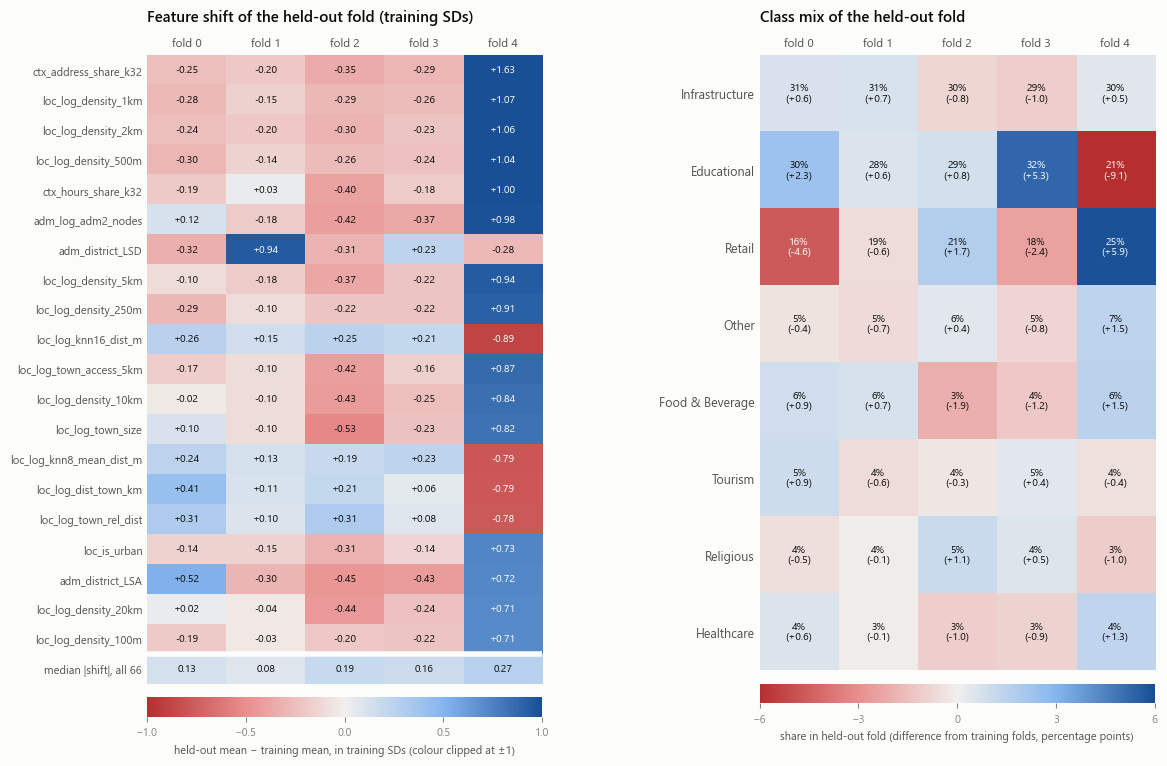

Labelled nodes per held-out fold: {0: 1182, 1: 1198, 2: 1183, 3: 1208, 4: 1181}
Median |shift| per fold: {0: 0.126, 1: 0.08, 2: 0.194, 3: 0.157, 4: 0.272}
Features with |shift| >= 0.5 per fold: {0: 2, 1: 1, 2: 5, 3: 0, 4: 26}
Largest class-mix gap: 9.1 pp (Educational, fold 4)

Mean |shift| per group and fold:
           0     1     2     3     4
loc     0.17  0.10  0.23  0.16  0.56
adm     0.19  0.16  0.30  0.20  0.39
struct  0.05  0.06  0.05  0.02  0.08
attr    0.13  0.04  0.17  0.11  0.23
ctx     0.22  0.10  0.29  0.19  0.50


In [9]:
FOLDS = sorted(df["fold"].unique())
shift = pd.DataFrame(index=FEATS, columns=FOLDS, dtype=float)
for f in FOLDS:
    tr, te = fold != f, fold == f
    shift[f] = (X[te].mean() - X[tr].mean()) / X[tr].std()
TOPN = 20
top_shift = shift.abs().max(axis=1).nlargest(TOPN).index
S = pd.concat([shift.loc[top_shift], shift.abs().median().to_frame("median |shift|, all 66").T])

class_mix = pd.DataFrame({f: df.loc[lab & (fold == f), "category"].value_counts(normalize=True) for f in FOLDS})
train_mix = pd.DataFrame({f: df.loc[lab & (fold != f), "category"].value_counts(normalize=True) for f in FOLDS})
mix_diff = (class_mix - train_mix).loc[CATS] * 100               # percentage points

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 8.6), gridspec_kw={"width_ratios": [1, 1], "wspace": 0.55})
lim = 1.0
im = ax.imshow(S.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(S.shape[0]):
    for j in range(S.shape[1]):
        v = S.iat[i, j]
        ax.text(j, i, f"{v:+.2f}" if i < TOPN else f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 else INK)
ax.axhline(TOPN - 0.5, color=SURFACE, lw=4)
ax.set_xticks(range(len(FOLDS)), [f"fold {f}" for f in FOLDS], fontsize=8.5, color=INK2)
ax.xaxis.tick_top(); ax.set_yticks(range(len(S)), S.index, fontsize=8, color=INK2)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Feature shift of the held-out fold (training SDs)", pad=24)
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.03, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
cb.set_label("held-out mean − training mean, in training SDs (colour clipped at ±1)", fontsize=8, color=INK2)

im2 = ax2.imshow(mix_diff.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -6, 6), aspect="auto")
for i in range(mix_diff.shape[0]):
    for j in range(mix_diff.shape[1]):
        ax2.text(j, i, f"{class_mix.loc[CATS[i], FOLDS[j]]:.0%}\n({mix_diff.iat[i, j]:+.1f})", ha="center",
                 va="center", fontsize=7.5, color="white" if abs(mix_diff.iat[i, j]) > 4 else INK)
ax2.set_xticks(range(len(FOLDS)), [f"fold {f}" for f in FOLDS], fontsize=8.5, color=INK2)
ax2.xaxis.tick_top(); ax2.set_yticks(range(len(CATS)), CATS, fontsize=9, color=INK2)
ax2.tick_params(length=0); ax2.grid(False)
for s in ax2.spines.values():
    s.set_visible(False)
ax2.set_title("Class mix of the held-out fold", pad=24)
cb2 = fig.colorbar(im2, ax=ax2, orientation="horizontal", fraction=0.05, pad=0.02, ticks=[-6, -3, 0, 3, 6])
cb2.outline.set_visible(False); cb2.ax.tick_params(labelsize=8)
cb2.set_label("share in held-out fold (difference from training folds, percentage points)", fontsize=8, color=INK2)
plt.show()

n_fold = df.loc[lab].groupby("fold").size()
print("Labelled nodes per held-out fold:", n_fold.to_dict())
print("Median |shift| per fold:", shift.abs().median().round(3).to_dict())
print("Features with |shift| >= 0.5 per fold:", (shift.abs() >= 0.5).sum().to_dict())
print(f"Largest class-mix gap: {mix_diff.abs().max().max():.1f} pp "
      f"({mix_diff.abs().stack().idxmax()[0]}, fold {mix_diff.abs().stack().idxmax()[1]})")
print("\nMean |shift| per group and fold:")
print(shift.abs().groupby(group_of).mean().reindex(GROUPS).round(2).to_string())

**Findings.**

- **Fold 4 is the urban fold.** It holds 55% of the nodes inside Maseru's town radius, and 65% of its nodes are
  urban against 26 to 33% in the other folds. Held out, it sits about 1 SD above the training folds on density at
  500 m to 5 km, 1.6 SD above on the area's address share, and about 0.8 SD closer to a town centre; 26 of the 66
  features shift by 0.5 SD or more. The other four folds shift by a median of 0.08 to 0.19 SD, with at most 5
  features above 0.5.
- **Its class mix differs too.** Fold 4 has 25% Retail and 21% Educational against about 19% and 30% in its training
  folds (+5.9 and −9.1 percentage points). Fold 2 has no nodes in Maseru town, and fold 1 is the closest match to
  its training folds. The EDA balanced how each class's nodes are spread over the folds; that does not make each
  fold's class mix equal, because urban blocks are denser and differently composed.
- **Structural encodings hardly shift** (mean |shift| 0.02 to 0.08 in every fold), while the `loc_` and `ctx_`
  features shift most. The structure of the k-NN graph looks the same everywhere; what varies between areas is how
  urban they are and how they were mapped.
- **For the model notebook:** per-fold scores will differ for reasons of geography, not only chance. Fold 4 tests
  transfer to the densest commercial area with fewer urban training examples, and fold 2 tests transfer to areas
  without Maseru. Report the per-fold scores and their spread next to the mean, and read a weak fold 4 as an
  urban-transfer result.

## 8. The mapping-bias caveat: what `attr_osm_id_rank` encodes

The feature notebook found `attr_osm_id_rank` to be the most label-informative feature (mutual information
0.46 nats) and the ReadMe traces this to OSM history: points and outlines are numbered in separate sequences, and
within each sequence ids follow mapping date. The chart splits the rank into those two parts. For each node, the
element with the smallest id (the one the rank is computed from) is read from `osm_ids`:

- **Left**: the share of each category whose smallest id is an outline (an OSM way or relation).
- **Right**: the id rank within each sequence (re-ranked among outline-based nodes and among point-based nodes
  separately, 0 = mapped first, 1 = mapped last), by category.

The mutual information printed below splits the rank's category information into these two parts.

Smallest id is an outline for 60% of nodes; their attr_osm_id_rank max 0.61 | point-based nodes: min 0.00, median 0.80


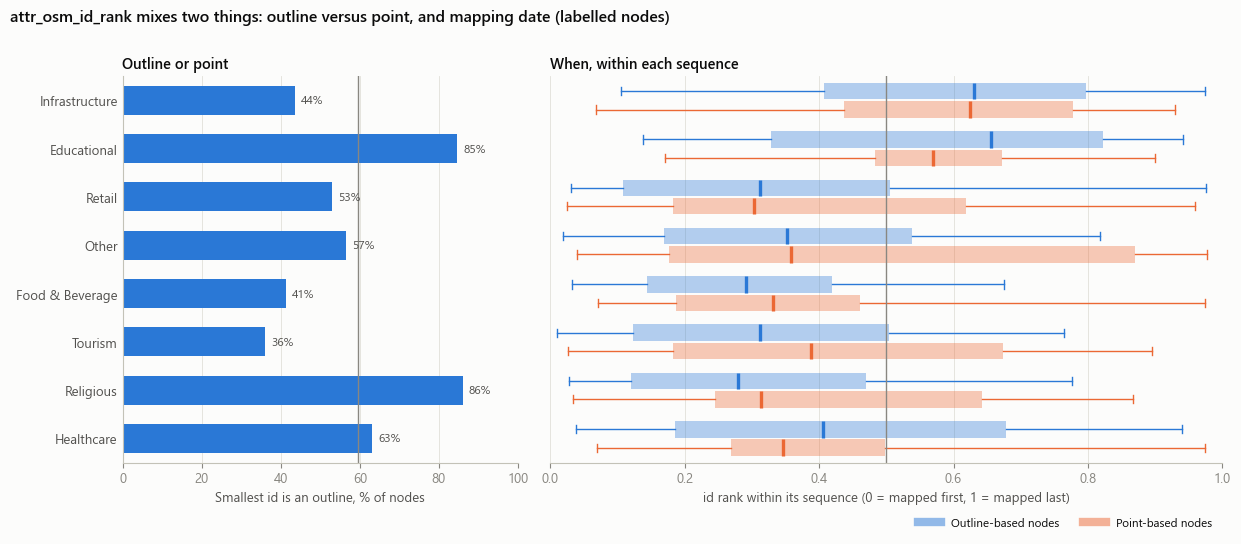


Mutual information with the category (nats): {'attr_osm_id_rank': np.float64(0.461), 'outline_or_point': np.float64(0.074), 'rank_within_sequence': np.float64(0.248)}
Type and within-sequence rank together (sequences placed side by side): 0.464

Median within-sequence rank by category:
                 outline-based  point-based  outline share
Infrastructure            0.63         0.62           0.44
Educational               0.66         0.57           0.85
Retail                    0.31         0.30           0.53
Other                     0.35         0.36           0.57
Food & Beverage           0.29         0.33           0.41
Tourism                   0.31         0.39           0.36
Religious                 0.28         0.31           0.86
Healthcare                0.41         0.35           0.63


In [10]:
from sklearn.feature_selection import mutual_info_classif


def smallest_element(ids):
    """(type, number) of the member with the smallest OSM id number."""
    parts = [(p.split("/")[0], int(p.split("/")[1])) for p in ids.split(";")]
    return min(parts, key=lambda t: t[1])


first = df["osm_ids"].map(smallest_element)
el_type = first.map(lambda t: "point" if t[0] == "node" else "outline")
is_outline = el_type.eq("outline").to_numpy()
rank = df["attr_osm_id_rank"].to_numpy()
within = pd.Series(rank).groupby(el_type.to_numpy()).rank(pct=True).to_numpy()     # rank inside each sequence
print(f"Smallest id is an outline for {is_outline.mean():.0%} of nodes; their attr_osm_id_rank max "
      f"{rank[is_outline].max():.2f} | point-based nodes: min {rank[~is_outline].min():.2f}, "
      f"median {np.median(rank[~is_outline]):.2f}")

o_share = pd.Series(is_outline[lab]).groupby(yl).mean().set_axis(CATS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [1, 1.7],
                                                                                    "wspace": 0.06})
yy = np.arange(len(CATS))
ax1.barh(yy, o_share * 100, color=BLUE, height=0.6)
for yv, v in zip(yy, o_share):
    ax1.text(v * 100 + 1.5, yv, f"{v:.0%}", va="center", fontsize=8.5, color=INK2)
ax1.axvline(is_outline[lab].mean() * 100, color=MUTED, lw=1)
ax1.set_xlim(0, 100); ax1.set_xlabel("Smallest id is an outline, % of nodes")
ax1.set_yticks(yy, CATS, color=INK2); ax1.tick_params(axis="y", length=0); ax1.grid(axis="y", visible=False)
ax1.set_ylim(len(CATS) - 0.5, -0.5)
ax1.set_title("Outline or point", fontsize=10.5)

h = 0.34
for s, (sel, colr, name) in enumerate([(is_outline, BLUE, "Outline-based nodes"),
                                       (~is_outline, ORANGE, "Point-based nodes")]):
    stats_ = []
    for k in range(len(CATS)):
        v = within[lab & sel][yl[sel[lab]] == k]
        stats_.append({"med": np.median(v), "q1": np.percentile(v, 25), "q3": np.percentile(v, 75),
                       "whislo": np.percentile(v, 5), "whishi": np.percentile(v, 95), "fliers": []})
    pos = yy + (s - 0.5) * (h + 0.04)
    ax2.bxp(stats_, positions=pos, vert=False, widths=h, patch_artist=True, showfliers=False,
            boxprops={"facecolor": colr, "edgecolor": "none", "alpha": 0.35},
            medianprops={"color": colr, "lw": 2.4}, whiskerprops={"color": colr, "lw": 1},
            capprops={"color": colr, "lw": 1}, manage_ticks=False)
    ax2.plot([], [], color=colr, lw=6, alpha=0.5, label=name)
ax2.axvline(0.5, color=MUTED, lw=1)
ax2.set_xlim(0, 1); ax2.set_xlabel("id rank within its sequence (0 = mapped first, 1 = mapped last)")
ax2.grid(axis="y", visible=False); ax2.tick_params(axis="y", length=0); ax2.spines["left"].set_visible(False)
ax2.set_title("When, within each sequence", fontsize=10.5)
ax2.legend(loc="lower right", fontsize=8.5, ncols=2, bbox_to_anchor=(1, -0.2))
fig.suptitle("attr_osm_id_rank mixes two things: outline versus point, and mapping date (labelled nodes)", x=0.01,
             ha="left", fontsize=11.5, fontweight="semibold")
fig.subplots_adjust(top=0.86, bottom=0.17, left=0.1, right=0.98); plt.show()

# Mutual information with the category (nats), same settings as the feature notebook
parts = pd.DataFrame({"attr_osm_id_rank": rank, "outline_or_point": is_outline.astype(float),
                      "rank_within_sequence": within})[lab]
mi = mutual_info_classif(parts.to_numpy(), yl, discrete_features=[False, True, False], n_neighbors=5,
                         random_state=SEED)
print("\nMutual information with the category (nats):", dict(zip(parts.columns, mi.round(3))))
mi_both = mutual_info_classif(np.c_[within[lab] + 2 * is_outline[lab]], yl, n_neighbors=5, random_state=SEED)[0]
print(f"Type and within-sequence rank together (sequences placed side by side): {mi_both:.3f}")
print("\nMedian within-sequence rank by category:")
print(pd.DataFrame({"outline-based": pd.Series(within[lab & is_outline]).groupby(yl[is_outline[lab]]).median().to_numpy(),
                    "point-based": pd.Series(within[lab & ~is_outline]).groupby(yl[~is_outline[lab]]).median().to_numpy(),
                    "outline share": o_share.to_numpy()}, index=CATS).round(2).to_string())

### Mapping sessions in the id order

The two parts above explain the rank's shift between categories, but mutual information also rewards *local*
structure: runs of consecutive ids that all belong to one category. Such runs appear when a mapper adds many places
of one type in a single session (all schools of a valley, all masts along a road). Below, each labelled node is one
tick at its position in id order (x = `attr_osm_id_rank`), one row per category. A dense cluster of ticks is a batch
of that category mapped together.

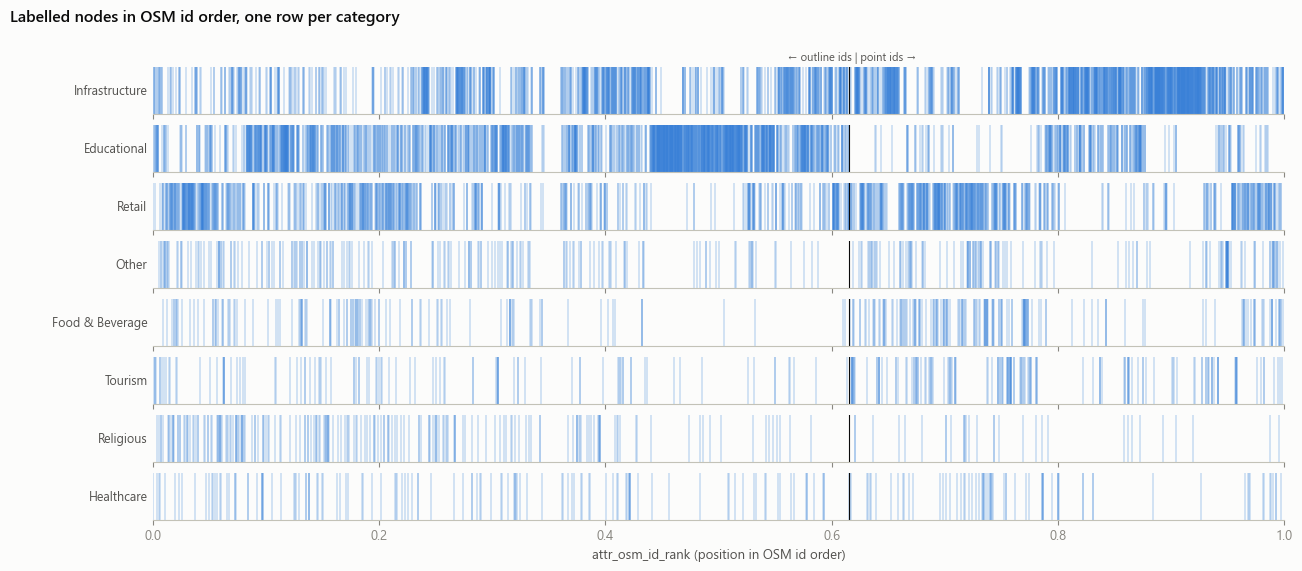

Nodes next to each other in id order with the same category: 48.6% (chance 21.8%)
Runs of >= 10 same-category nodes: 46, holding 850 nodes (14% of labelled nodes)
Those runs by category: {'Infrastructure': 24, 'Educational': 20, 'Retail': 2}
Runs of >= 10 that span more than one CV fold: 44 of 46

Longest runs:
  Infrastructure   64 nodes | districts {'Maseru': 56, "Mohale's Hoek": 4} | folds [0, 1, 2, 3, 4]
  Infrastructure   44 nodes | districts {'Berea': 26, 'Maseru': 18} | folds [0, 1, 3, 4]
  Educational      42 nodes | districts {'Maseru': 29, 'Thaba-Tseka': 7} | folds [0, 1, 2, 3, 4]
  Infrastructure   32 nodes | districts {'Maseru': 30, 'Thaba-Tseka': 1} | folds [0, 1, 2, 3]
  Educational      32 nodes | districts {'Mokhotlong': 15, "Qacha's Nek": 13} | folds [0, 1, 2, 3, 4]
  Educational      30 nodes | districts {"Qacha's Nek": 21, 'Thaba-Tseka': 9} | folds [0, 1, 2, 3, 4]


In [11]:
rl = rank[lab]
fig, axes = plt.subplots(len(CATS), 1, figsize=(13, 5.8), sharex=True)
for k, (ax, cat) in enumerate(zip(axes, CATS)):
    ax.vlines(rl[yl == k], 0, 1, color=BLUE, lw=0.35, alpha=0.8)
    ax.set_yticks([]); ax.set_ylim(0, 1); ax.grid(False)
    ax.set_ylabel(cat, rotation=0, ha="right", va="center", fontsize=9, color=INK2)
    for s in ["left", "top", "right"]:
        ax.spines[s].set_visible(False)
    ax.axvline(rank[is_outline].max(), color=INK, lw=0.8)
axes[0].text(rank[is_outline].max() + 0.003, 1.15, "← outline ids | point ids →", fontsize=8, color=INK2,
             transform=axes[0].get_xaxis_transform(), ha="center")
axes[-1].set_xlim(0, 1); axes[-1].set_xlabel("attr_osm_id_rank (position in OSM id order)")
fig.suptitle("Labelled nodes in OSM id order, one row per category", x=0.01, ha="left", fontsize=11.5,
             fontweight="semibold")
fig.subplots_adjust(top=0.88, bottom=0.1, left=0.12, right=0.99, hspace=0.25); plt.show()

# Runs of the same category in id order
o = np.argsort(rl, kind="stable")
ys = yl[o]
runs = np.diff(np.flatnonzero(np.r_[True, ys[1:] != ys[:-1], True]))
starts = np.r_[0, np.cumsum(runs)[:-1]]
print(f"Nodes next to each other in id order with the same category: {(ys[1:] == ys[:-1]).mean():.1%} "
      f"(chance {(pd.Series(yl).value_counts(normalize=True) ** 2).sum():.1%})")
print(f"Runs of >= 10 same-category nodes: {(runs >= 10).sum()}, holding {runs[runs >= 10].sum():,} nodes "
      f"({runs[runs >= 10].sum() / len(ys):.0%} of labelled nodes)")
run_cat = pd.Series([CATS[ys[s]] for s in starts[runs >= 10]]).value_counts()
print("Those runs by category:", run_cat.to_dict())
fold_l = fold[li][o]
multi = sum(len(set(fold_l[s:s + r])) > 1 for s, r in zip(starts[runs >= 10], runs[runs >= 10]))
print(f"Runs of >= 10 that span more than one CV fold: {multi} of {(runs >= 10).sum()}")
print("\nLongest runs:")
a1_l = df["adm1_name"].to_numpy()[li][o]
for b in np.argsort(runs)[::-1][:6]:
    seg = slice(starts[b], starts[b] + runs[b])
    print(f"  {CATS[ys[starts[b]]]:<15} {runs[b]:>3} nodes | districts {pd.Series(a1_l[seg]).value_counts().head(2).to_dict()}"
          f" | folds {sorted(set(fold_l[seg].tolist()))}")

**Findings.**

- **Outline versus point.** 60% of nodes take their rank from an outline id, and those all rank at or below 0.61;
  point-based nodes have a median rank of 0.80. Educational and Religious nodes are 85% and 86% outline-based,
  Tourism and Food & Beverage only 36% and 41%, so the outline share alone moves a category's typical rank.
- **Mapping date within each sequence.** Both sequences give the same order: Infrastructure and Educational were
  mapped late (median rank within the sequence 0.57 to 0.66), while Retail, Other, Food & Beverage, Tourism and
  Religious were mapped early (0.28 to 0.39); Healthcare falls in between. Two independent id sequences agreeing
  points to a real feature of the mapping history, not noise.
- **Mapping sessions are the sharpest part.** Nodes next to each other in id order share a category 49% of the
  time (22% by chance). 46 runs of 10 or more same-category nodes hold 14% of the labelled nodes, nearly all
  Infrastructure (24 runs) or Educational (20). The barcode shows them: a solid block of schools among the outline
  ids around rank 0.44 to 0.60, and dense Infrastructure among the newest point ids. The rank acts as a
  "which mapping session" identifier, which is why its mutual information (0.46 nats; 0.25 for the within-sequence
  date alone, 0.07 for outline versus point alone) is far higher than its rank-based ε² in Section 2.
- **Spatial CV does not hold these sessions out.** 44 of the 46 long runs span more than one fold (the six longest
  cover four or five folds each), because a session follows a mapper across the country, not a 5 km block. A model
  given `attr_osm_id_rank` can learn "ids in this range are schools" from training folds and apply it to the
  held-out fold. That is a shortcut through OSM editing history that would not carry over to new data.
- **For the model notebook:** this confirms the ReadMe's advice. Report results with and without the three
  `osm_id_rank` columns; the gap measures how much the model relies on mapping sessions. The version without them
  is the one that speaks about places.

## 9. Summary

| Section | What the figures show |
|---|---|
| 1. Feature atlas | The features are well-conditioned: 43 of 50 continuous features have \|skew\| ≤ 1; the rest are zero-inflated counts. Spikes are shared values (Maseru's wide-radius counts, one value per sub-district). |
| 2. Category profiles | Local density and spacing (`loc_`) and the node's own mapping attributes (`attr_`) separate the categories; shape, structure and district features barely do on their own. Retail, Food & Beverage and Other share one dense-cluster profile; Educational is its mirror image; Tourism has the weakest profile. |
| 3. Overlap | Even the strongest features overlap heavily between categories. Only Educational stands apart on its own features. |
| 4. Redundancy | The 66 columns span about 25 directions (90% of variance). One large urban–rural block; shape and structure features are nearly independent of it. |
| 5. Features on the graph | Most features are almost constant across an edge (median r = 0.97). The node's own `attr_` features are not, and averaging them over neighbours wipes out their category signal. |
| 6. Same-category neighbours | Features lead for Educational, Infrastructure and Religious; graph neighbours lead on held-out areas for Retail, Tourism and Other; Healthcare is near chance on both. Standardised district one-hots split the feature space by district. |
| 7. CV folds | Fold 4 is the urban fold (65% urban, 55% of Maseru town) and differs in both features and class mix; structural encodings are stable across folds. |
| 8. Mapping bias | `attr_osm_id_rank` encodes outline versus point, mapping date, and above all mapping sessions (runs of same-category ids) that cross the spatial folds. |

**Takeaways for the model notebook**

1. **Keep the node's own features separate from the neighbour aggregate** (GraphSAGE, GraphConv with a root weight, or
   residual connections), not a plain GCN average, so the `attr_` signal survives message passing (Section 5).
2. **Try scaling only the continuous features**, leaving the 16 binary indicators as 0/1, so rare district
   indicators do not become the largest inputs (Section 6).
3. **Report per-class and per-fold scores, not only the mean macro-F1.** Expect confusion among Retail, Food &
   Beverage and Other, weak Healthcare, and a harder fold 4 (Sections 3, 6, 7).
4. **Report results with and without the three `osm_id_rank` columns**; the gap measures reliance on mapping sessions
   (Section 8).
5. **Use group ablations** (`loc_`, `adm_`, `struct_`, `attr_`, `ctx_`) to test the shape, structure and district
   features, which carry little signal on their own but are not redundant with the rest (Sections 2, 4).

All figures here are descriptive, computed over all folds, and nothing in this notebook feeds back into the feature
set in `poi_engineered.csv`.